# Automated seizure detection from wearable behind-the-ear EEG (SeizeIT2)

**Goal.** Detect epileptic seizures from the two behind-the-ear EEG channels of the SeizeIT2 wearable
(OpenNeuro ds005873) with a feature-based XGBoost classifier. Clinically useful wearable detection needs
**high seizure sensitivity with few false alarms** (each false alarm wakes up a patient or carer), so the whole
pipeline is designed and tuned around that trade-off.

**Research questions**

* **RQ1** – Does detection sensitivity depend on the **seizure type** (focal aware, focal impaired awareness,
  focal-to-bilateral tonic-clonic, ...)?
* **RQ2** – Does detection sensitivity depend on the **seizure duration**?

**Pipeline overview**

| Step | What | Why |
|---|---|---|
| 1 | Read EDF (2 channels), convert **V → µV**, band-pass 1–25 Hz | MNE returns volts; thresholds are in µV |
| 2 | 2 s windows, 1 s step (50 % overlap) | standard for wearable EEG (Vandecasteele et al., 2020) |
| 3 | 21 features × 2 channels = **42 features** (+ 42 temporal-context features, Section 6) | time, frequency and entropy descriptors; change vs. the previous 60 s |
| 4 | Log transform + causal amplitude normalisation | removes slow amplitude drifts between patients/recordings |
| 5 | **Label-blind** artifact flag (RMS outside 13–150 µV) | the same rule can be applied to unseen data |
| 6 | **Nested patient-wise cross-validation** (10 folds); Optuna tunes XGBoost using training patients only | honest estimate of performance on a *new* patient |
| 7 | Post-processing: threshold, 8-out-of-10 rule, event merging | turns window predictions into alarms |
| 8 | **Event-level** scoring (SzCORE): sensitivity, false alarms / hour | what matters clinically |

**References**

* Vandecasteele K. et al. (2020). *Visual seizure annotation and automated seizure detection using behind-the-ear
  electroencephalographic channels.* Epilepsia 61(4):766–775.
* Bhagubai M. et al. (2025). *SeizeIT2: Wearable dataset of patients with focal epilepsy.* Scientific Data
  (arXiv:2502.01224).
* Dan J. et al. (2024). *SzCORE: Seizure Community Open-source Research Evaluation framework for the validation of
  EEG-based automated seizure detection algorithms.* Epilepsia.
* Chen T. & Guestrin C. (2016). *XGBoost: A scalable tree boosting system.* KDD.
* Akiba T. et al. (2019). *Optuna: A next-generation hyperparameter optimization framework.* KDD.

**How to run.** Execute the cells top to bottom. Cell 3 (feature extraction) and Cell 6 (cross-validation) are
long; both save their results to disk and **resume** where they stopped if interrupted.
Set `QUICK_TEST = True` first to check that everything runs on a few subjects.

## 1. Configuration

All settings live in one place. Paths can also be given through environment variables
(`SEIZEIT2_DATA`, `SEIZURE_PROJECT`) so that the notebook runs unchanged on another computer.

In [ ]:
# CELL 1: Imports & configuration

import os, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

# Paths 

# Default layout: run the notebook from the notebooks/ folder of the repository; the project folder is its parent.
# Both paths can be overridden with environment variables (see README).
PROJECT_DIR   = Path(os.environ.get('SEIZURE_PROJECT', '..')).resolve()
DATA_PATH     = Path(os.environ.get('SEIZEIT2_DATA', PROJECT_DIR / 'data' / 'seizeit2'))
PROCESSED_DIR = PROJECT_DIR / 'processed_v3'      # new folder: old .npz files are NOT reused
RESULTS_DIR   = PROJECT_DIR / 'results'
FOLD_DIR      = RESULTS_DIR / 'loso_folds'        # one checkpoint per outer fold (fold_XX.pkl) + test-patient probabilities
                                                  # (folder name kept from an earlier leave-one-subject-out version)
FIG_DIR       = PROJECT_DIR / 'figures'
for d in (PROCESSED_DIR, RESULTS_DIR, FOLD_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Signal processing 

N_CHANNELS      = 2            # first two EDF channels = BTEleft SD, CROSStop SD
WINDOW_SEC      = 2.0          # window length
STEP_SEC        = 1.0          # 50 % overlap
BAND            = (1.0, 25.0)  # band-pass for the EEG features
HF_BAND         = (40.0, 80.0) # high-frequency (muscle) band, computed on a broadband signal
FILTER_ORDER    = 4
# Artifact rule. The SeizeIT2 baseline (Bhagubai et al. 2025) rejects windows with RMS < 13 µV or > 150 µV.
# On these recordings the 13 µV bound keeps only ~12 % of background and ~45 % of seizure windows (typical RMS is
# ~10 µV behind the ear), so only flat signals (< 2 µV, electrode off) are rejected here; Cell 4 reports both.
# The rule is applied when the data are LOADED (Cell 4), so it can be changed without re-extracting features.
RMS_MIN_UV      = 2.0          # below: flat signal / electrode disconnected   (paper: 13.0)
RMS_MAX_UV      = 150.0        # above: movement artifact
NORM_RMS_RANGE  = (2.0, 150.0) # windows used to update the amplitude normalisation (not flat, not saturated)
NORM_ALPHA      = 0.99         # memory of the causal amplitude normalisation (~100 s)
MIN_OVERLAP_SEC = 1.0          # a window is 'ictal' if >= 1 s of it lies inside a seizure
FEATURE_VERSION = 4            # bump to force re-extraction
N_JOBS_PREPROC  = 1            # subjects processed in parallel; keep 1 with 4-8 GB RAM (each needs ~1 GB)
FEATURE_CHUNK   = 5000         # windows per feature batch (limits memory use)

#  Model & cross-validation 

RANDOM_SEED        = 42
UNDERSAMPLE_RATIO  = 5         # interictal : ictal windows in the training set
ALARM_K, ALARM_N   = 8, 10     # alarm if >= 8 of the last 10 windows (10 s) are above threshold (SeizeIT2 paper)
N_OUTER_FOLDS      = 10        # patient-wise cross-validation folds (set = number of patients for LOSO)
INNER_VAL_FRACTION = 0.2       # fraction of TRAINING patients used for Optuna and the threshold
OPTUNA_VAL_BACKGROUND = 300_000  # background windows (random, fixed) used to compute the Optuna AUPR
FA_TARGET_PER_H    = 1.0       # MAIN result: threshold = highest sensitivity with <= 1 false alarm / hour (training patients)
EXTRA_FA_TARGETS   = [2.0, 3.0]  # additional operating points, same models (reported in Section 7)
BASELINE_RESULTS_DIR = PROJECT_DIR / 'results_baseline'   # 42-feature run, for the McNemar comparison (optional)
THRESHOLD_GRID     = np.round(np.arange(0.05, 0.951, 0.025), 3)
PAPER_THRESHOLD    = 0.5       # fixed threshold of the SeizeIT2 baseline, reported for comparison
CONTEXT_SEC        = 60        # temporal context: each feature minus its mean over the previous 60 s (0 = off)

# Optuna hyper-parameter search (inside every fold, on training patients only)
N_OPTUNA_TRIALS = 15
# The search space is deliberately limited to SIMPLE, regularised models (shallow trees, a minimum leaf size,
# subsampling) so that the tuning itself cannot produce an over-fitted model.
def suggest_xgb_params(trial):
    return dict(
        n_estimators     = trial.suggest_int('n_estimators', 100, 500, step=50),          # number of trees
        max_depth        = trial.suggest_int('max_depth', 2, 6),                          # tree depth
        learning_rate    = trial.suggest_float('learning_rate', 0.02, 0.2, log=True),     # step size
        subsample        = trial.suggest_float('subsample', 0.6, 1.0),                    # windows per tree
        colsample_bytree = trial.suggest_float('colsample_bytree', 0.5, 1.0),             # features per tree
        min_child_weight = trial.suggest_int('min_child_weight', 5, 50),                  # minimum leaf size
        reg_lambda       = trial.suggest_float('reg_lambda', 0.5, 10.0, log=True),        # L2 regularisation
    )
XGB_FIXED = dict(tree_method='hist', n_jobs=-1, random_state=RANDOM_SEED, verbosity=0)
DEFAULT_PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, min_child_weight=10, reg_lambda=1.0)   # first trial (sensible start)

# Event-level scoring (SzCORE, Dan et al. 2024)

TOL_BEFORE_SEC = 30            # an alarm up to 30 s before onset still counts
TOL_AFTER_SEC  = 60            # ... or up to 60 s after the end
MERGE_GAP_SEC  = 90            # alarms closer than 90 s are one event
MAX_EVENT_SEC  = 300           # alarms longer than 5 min are split

# Quick test mode 

QUICK_TEST       = os.environ.get('QUICK_TEST', '0') == '1'   # or simply set True here
QUICK_N_SUBJECTS = 10
if QUICK_TEST:
    N_OPTUNA_TRIALS = 4

BOOT_B = 2000                  # patient-level bootstrap resamples for confidence intervals
np.random.seed(RANDOM_SEED)
print(f'Data     : {DATA_PATH}  (exists: {DATA_PATH.exists()})')
print(f'Project  : {PROJECT_DIR}')
print(f'Quick test mode: {QUICK_TEST}')

Data     : <repository>\data\seizeit2  (exists: True)
Project  : <repository>
Quick test mode: False


### Computational environment and configuration record

The next cell records the software versions, the hardware and all settings of Cell 1 in `results/`
(`environment.json`, `config_used.json`) and writes `requirements_lock.txt` with the exact package versions, so that
the analysis can be re-run in the same environment.

In [ ]:
# CELL 1a: Record environment and configuration (reproducibility)

import sys, platform, importlib.metadata as md_

PACKAGES = ['numpy', 'scipy', 'pandas', 'scikit-learn', 'xgboost', 'optuna', 'mne', 'antropy',
            'matplotlib', 'joblib', 'tqdm', 'statsmodels']
versions = {}
for p_ in PACKAGES:
    try:    versions[p_] = md_.version(p_)
    except md_.PackageNotFoundError: pass
ENV = dict(python=sys.version.split()[0], platform=platform.platform(), processor=platform.processor(),
           cpu_count=os.cpu_count(), packages=versions,
           note='XGBoost uses n_jobs=-1 (all cores); results were identical in repeated runs on the same machine')
(RESULTS_DIR / 'environment.json').write_text(json.dumps(ENV, indent=2))
(PROJECT_DIR / 'requirements_lock.txt').write_text('\n'.join(f'{k}=={v}' for k, v in versions.items()) + '\n')

CONFIG = {k: (v if isinstance(v, (int, float, str, bool, list, tuple, dict)) or v is None else str(v))
          for k, v in globals().items() if k.isupper() and not k.startswith('_')}
CONFIG['THRESHOLD_GRID'] = [float(x) for x in THRESHOLD_GRID]
(RESULTS_DIR / 'config_used.json').write_text(json.dumps(CONFIG, indent=2, default=str))
print(f"Python {ENV['python']} | {ENV['platform']} | {ENV['cpu_count']} CPUs")
print(', '.join(f'{k} {v}' for k, v in versions.items()))

Python 3.11.9 | Windows-10-10.0.26100-SP0 | 4 CPUs
numpy 2.4.6, scipy 1.17.1, pandas 3.0.5, scikit-learn 1.9.0, xgboost 3.2.0, optuna 5.0.0, mne 1.12.1, antropy 0.2.2, matplotlib 3.11.1, joblib 1.6.0, tqdm 4.70.0


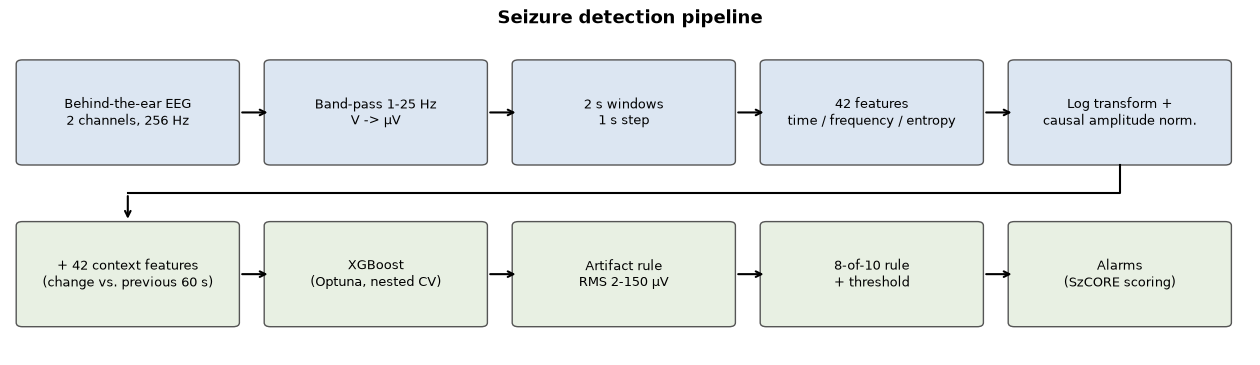

In [ ]:
# CELL 1b: Pipeline diagram (figure for the methods section)

from matplotlib.patches import FancyBboxPatch

steps = [['Behind-the-ear EEG\n2 channels, 256 Hz', 'Band-pass 1-25 Hz\nV -> µV', '2 s windows\n1 s step',
          '42 features\ntime / frequency / entropy', 'Log transform +\ncausal amplitude norm.'],
         ['+ 42 context features\n(change vs. previous 60 s)', 'XGBoost\n(Optuna, nested CV)',
          'Artifact rule\nRMS 2-150 µV', '8-of-10 rule\n+ threshold', 'Alarms\n(SzCORE scoring)']]
fig, ax = plt.subplots(figsize=(16, 4.2)); ax.set_xlim(0, 10); ax.set_ylim(0, 4); ax.axis('off')
cols = ['#DCE6F2', '#E8F0E3']
pos = {}
for r, row in enumerate(steps):
    for c, txt in enumerate(row):
        x, y = 0.1 + c * 2, 2.4 - r * 2
        ax.add_patch(FancyBboxPatch((x, y), 1.7, 1.2, boxstyle='round,pad=0.05', fc=cols[r], ec='#555555'))
        ax.text(x + 0.85, y + 0.6, txt, ha='center', va='center', fontsize=9.5)
        pos[(r, c)] = (x, y)
for r in range(2):
    for c in range(4):
        x, y = pos[(r, c)]
        ax.annotate('', xy=(x + 2.0, y + 0.6), xytext=(x + 1.75, y + 0.6), arrowprops=dict(arrowstyle='->', lw=1.5))
x1, y1 = pos[(0, 4)]; x2, y2 = pos[(1, 0)]
ym = (y1 + y2 + 1.2) / 2                                   # route: down, left, down
ax.plot([x1 + 0.85, x1 + 0.85, x2 + 0.85], [y1 - 0.05, ym, ym], c='k', lw=1.5)
ax.annotate('', xy=(x2 + 0.85, y2 + 1.25), xytext=(x2 + 0.85, ym), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.set_title('Seizure detection pipeline', fontsize=13, fontweight='bold')
plt.savefig(FIG_DIR / 'pipeline.png', dpi=150, bbox_inches='tight'); plt.show()

## 2. Signal processing and feature extraction

**Units.** `mne.io.read_raw_edf` always returns **volts**. All amplitude thresholds are in µV, so the signal is
multiplied by 10⁶ immediately after reading. (Forgetting this makes every window look "flat": RMS ≈ 2·10⁻⁵ < 13.)

**Filtering.** A zero-phase 4th-order Butterworth band-pass (1–25 Hz) keeps the frequency range in which
behind-the-ear seizure activity is visible and removes drift and line noise. The **high-frequency band (40–80 Hz)
is computed on a separate broadband copy** of the signal — on the 1–25 Hz signal it would always be ~0.
High-frequency power is mainly muscle activity, which helps the model recognise movement artifacts and
tonic-clonic seizures.

**Features (per channel, ×2 channels = 42):**

| # | Feature | Domain |
|---|---|---|
| 0–2 | zero crossings, local maxima, local minima | time |
| 3–4 | skewness, kurtosis | time |
| 5 | RMS amplitude | time |
| 6 | total power (1–25 Hz) | frequency |
| 7 | peak frequency | frequency |
| 8–15 | absolute and relative power: δ 1–3, θ 4–8, α 9–13, β 14–20 Hz | frequency |
| 16–17 | absolute and relative power 40–80 Hz | frequency |
| 18 | sample entropy | entropy |
| 19 | Shannon entropy of the amplitude distribution (64 bins) | entropy |
| 20 | spectral entropy (normalised) | entropy |

**Normalisation.** Amplitude and power features are log-transformed. The absolute amplitude features are then
expressed **relative to the recent background** of the same recording:
`log(x_t) − EMA_t(log x)`, i.e. `log(x_t / typical level)`. The exponential moving average (EMA, α = 0.99, ≈100 s
memory) is **causal** (uses only the past) and is updated only on artifact-free windows, so it could run on a
real device. This removes differences in electrode impedance and skin contact between patients.
(Tree models are insensitive to monotonic transforms, so the log itself does not change XGBoost; it matters because it
turns the normalisation into a ratio.)

**Analysis choices (recorded explicitly).**
* *Transformation:* natural logarithm, zeros handled as `log(max(x, 1e-12))`; applied to the 12 strictly positive
  amplitude/power features (`LOG_IDX`).
* *Scaling:* only the 7 absolute amplitude/power features (`NORM_IDX`) are normalised, per recording, by their own
  causal running mean (no statistics are shared between patients, so no information crosses the train/test split).
* *Missing values:* sample entropy is undefined for flat windows; these values are kept as missing (NaN), which
  XGBoost handles natively. No imputation is used.
* *Feature filtering:* none – all 42 (+42 context) features are used; the model is never given a feature subset
  chosen with the labels.

**Labels.** A window is labelled *ictal* (1) when at least 1 s of it overlaps an annotated seizure
(`eventType` starting with `sz_` in the `_events.tsv` file). Seizure annotations are also stored as **events**
(onset, duration, type) so that evaluation is done against the true seizures, not against windows.

**Artifacts – label-blind rule.** A window is flagged as artifact when the RMS of *either* channel is outside
2–150 µV (flat signal / electrode disconnected, or movement). The SeizeIT2 baseline (Bhagubai et al., 2025) uses
13–150 µV, but behind-the-ear signals are small (median RMS ≈ 10 µV): on this data the 13 µV bound keeps only
12 % of the interictal and 45 % of the ictal windows, so more than half of the seizure activity could never be
detected. The RMS of every window is stored and the rule is applied when the data are loaded (Cell 4), which
reports the fraction kept by both rules. The rule does not use labels, so it is applied identically to training
and test data:

* *training*: flagged interictal windows are removed (seizure windows are always kept, which is allowed because
  labels are known for training data);
* *testing*: flagged windows cannot raise an alarm (probability set to 0). Removing only the *interictal* artifact
  windows of a test patient would use the labels and make the results look better than they are.

In [ ]:
# CELL 2: Preprocessing & feature functions

import mne
import antropy as ant
from scipy.signal import butter, sosfiltfilt, welch
from numpy.lib.stride_tricks import sliding_window_view

_trapz = getattr(np, 'trapezoid', None) or np.trapz   # numpy >= 2 renamed trapz

FEATURE_NAMES_1CH = ['zero_cross', 'n_max', 'n_min', 'skew', 'kurtosis', 'rms',
                     'total_power', 'peak_freq',
                     'delta_abs', 'delta_rel', 'theta_abs', 'theta_rel',
                     'alpha_abs', 'alpha_rel', 'beta_abs', 'beta_rel',
                     'hf_abs', 'hf_rel', 'sample_entropy', 'shannon_entropy', 'spectral_entropy']
CHANNEL_NAMES  = ['ch1', 'ch2']   # ch1 = same-side (BTEleft/BTEright), ch2 = cross-head (or contralateral BTE)
FEATURE_NAMES  = [f'{c}_{f}' for c in CHANNEL_NAMES for f in FEATURE_NAMES_1CH]
N_FEAT_1CH     = len(FEATURE_NAMES_1CH)            # 21
LOG_IDX  = [5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]   # strictly positive amplitude / power features
NORM_IDX = [5, 6, 8, 10, 12, 14, 16]                     # absolute amplitude / power -> normalised
BANDS    = [(1, 3), (4, 8), (9, 13), (14, 20)]


def bandpass(data, fs, lo, hi, order=FILTER_ORDER):
    # Zero-phase Butterworth band-pass (second-order sections = numerically stable).
    hi  = min(hi, 0.45 * fs)
    sos = butter(order, [lo, hi], btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, data, axis=-1)


def make_windows(x, fs):
    # (channels, samples) -> (n_windows, channels, win) as a view, plus window start times (s)
    win, step = int(WINDOW_SEC * fs), int(STEP_SEC * fs)
    if x.shape[1] < win:
        return np.empty((0, x.shape[0], win)), np.empty(0)
    w = sliding_window_view(x, win, axis=1)[:, ::step, :]          # (ch, n, win)
    return w.transpose(1, 0, 2), np.arange(w.shape[1]) * STEP_SEC


def channel_features(x, xb, fs):
    # x: (n, win) band-passed 1-25 Hz, xb: (n, win) broadband. Returns (n, 21).
    x, xb = np.asarray(x, np.float64), np.asarray(xb, np.float64)
    n = x.shape[0]
    F = np.empty((n, N_FEAT_1CH))
    F[:, 0] = (np.diff(np.signbit(x), axis=1)).sum(1)
    mid = x[:, 1:-1]
    F[:, 1] = ((mid > x[:, :-2]) & (mid > x[:, 2:])).sum(1)
    F[:, 2] = ((mid < x[:, :-2]) & (mid < x[:, 2:])).sum(1)
    d  = x - x.mean(1, keepdims=True)                           # skewness / kurtosis from central moments
    m2 = (d ** 2).mean(1); m2s = np.where(m2 > 0, m2, np.nan)
    F[:, 3] = (d ** 3).mean(1) / m2s ** 1.5
    F[:, 4] = (d ** 4).mean(1) / m2s ** 2 - 3.0                  # excess (Fisher) kurtosis
    F[:, 5] = np.sqrt((x ** 2).mean(1))

    f, P = welch(x, fs=fs, nperseg=int(fs), axis=-1)            # 1 Hz resolution
    inb  = (f >= BAND[0]) & (f <= BAND[1])
    tp   = np.maximum(_trapz(P[:, inb], f[inb], axis=1), 1e-12)
    F[:, 6] = tp
    F[:, 7] = f[inb][np.argmax(P[:, inb], axis=1)]
    for j, (lo, hi) in enumerate(BANDS):
        m  = (f >= lo) & (f <= hi)
        bp = _trapz(P[:, m], f[m], axis=1)
        F[:, 8 + 2 * j], F[:, 9 + 2 * j] = bp, bp / tp

    fb, Pb = welch(xb, fs=fs, nperseg=int(fs), axis=-1)
    allb   = fb >= 1
    hfm    = (fb >= HF_BAND[0]) & (fb <= min(HF_BAND[1], 0.45 * fs))
    tb     = np.maximum(_trapz(Pb[:, allb], fb[allb], axis=1), 1e-12)
    hf     = _trapz(Pb[:, hfm], fb[hfm], axis=1) if hfm.sum() > 1 else np.zeros(n)
    F[:, 16], F[:, 17] = hf, hf / tb

    # Sample entropy is O(N^2) and the slowest feature. The signal is already low-pass filtered at 25 Hz, so it is
    # computed on the signal down-sampled to ~64 Hz (no information above 25 Hz is lost; ~16x faster).
    ds = max(1, int(fs // 64))
    se = np.empty(n)
    for i in range(n):
        try:    se[i] = ant.sample_entropy(x[i, ::ds])
        except Exception: se[i] = np.nan
    se[~np.isfinite(se)] = np.nan                                 # XGBoost handles NaN natively
    F[:, 18] = se

    # Shannon entropy of the amplitude histogram (64 equal-width bins between min and max of the window)
    mn, mx = x.min(1, keepdims=True), x.max(1, keepdims=True)
    b  = np.clip(((x - mn) / np.maximum(mx - mn, 1e-12) * 64).astype(np.int64), 0, 63)
    c  = np.bincount((b + 64 * np.arange(n)[:, None]).ravel(), minlength=64 * n).reshape(n, 64)
    p  = c / x.shape[1]
    F[:, 19] = -(np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0)).sum(1)

    p = P[:, inb] / np.maximum(P[:, inb].sum(1, keepdims=True), 1e-20)
    F[:, 20] = -(p * np.log2(p + 1e-20)).sum(1) / np.log2(inb.sum())
    return F


def normalise(X, valid, alpha=NORM_ALPHA):
    # Log-transform + causal EMA normalisation of absolute amplitude features (one recording).
    X = X.copy()
    for ch in range(N_CHANNELS):
        o = ch * N_FEAT_1CH
        cols = [o + i for i in LOG_IDX]
        X[:, cols] = np.log(np.maximum(X[:, cols], 1e-12))
        ncols = [o + i for i in NORM_IDX]
        if not valid.any():
            X[:, ncols] = 0.0
            continue
        running = X[np.argmax(valid), ncols].copy()          # first artifact-free window
        out = np.empty((len(X), len(ncols)))
        V = X[:, ncols]
        for i in range(len(X)):
            if valid[i]:
                running = alpha * running + (1 - alpha) * V[i]
            out[i] = V[i] - running                           # = log(x / typical level)
        X[:, ncols] = out
    return X


def label_windows(starts, sz_events):
    # 1 if a window overlaps a seizure by >= MIN_OVERLAP_SEC (or by the whole seizure if shorter).
    y = np.zeros(len(starts), dtype=np.int8)
    for on, dur in sz_events:
        ov = np.minimum(starts + WINDOW_SEC, on + dur) - np.maximum(starts, on)
        y[ov >= min(MIN_OVERLAP_SEC, dur) - 1e-9] = 1
    return y


def process_recording(edf_path, tsv_path):
    raw = mne.io.read_raw_edf(edf_path, preload=False, verbose=False)
    fs  = float(raw.info['sfreq'])
    duration = raw.n_times / fs

    ev  = pd.read_csv(tsv_path, sep='\t')
    sz  = ev[ev['eventType'].astype(str).str.startswith('sz_')]
    sz_events = list(zip(sz['onset'].astype(float), sz['duration'].astype(float)))
    sz_types  = sz['eventType'].astype(str).tolist()

    # one channel at a time + float32 storage keeps memory low (long recordings, 4 GB RAM)
    xf = np.empty((N_CHANNELS, raw.n_times), np.float32)
    xb = np.empty((N_CHANNELS, raw.n_times), np.float32)
    for c in range(N_CHANNELS):
        x = raw.get_data(picks=[c])[0] * 1e6                       # VOLTS -> µV
        xb[c] = bandpass(x, fs, 1.0, 0.45 * fs)
        xf[c] = bandpass(x, fs, *BAND)
        del x
    W, starts = make_windows(xf, fs)
    Wb, _     = make_windows(xb, fs)
    if len(W) == 0:
        return None, duration, sz_events, sz_types
    # features in batches of FEATURE_CHUNK windows so that long recordings fit in memory
    X = np.vstack([np.hstack([channel_features(W[i:i + FEATURE_CHUNK, c], Wb[i:i + FEATURE_CHUNK, c], fs)
                              for c in range(N_CHANNELS)])
                   for i in range(0, len(W), FEATURE_CHUNK)])
    rms    = X[:, [c * N_FEAT_1CH + 5 for c in range(N_CHANNELS)]].copy()     # RMS per channel (µV)
    ema_ok = np.all((rms >= NORM_RMS_RANGE[0]) & (rms <= NORM_RMS_RANGE[1]), axis=1)
    X = normalise(X, ema_ok)
    y = label_windows(starts, sz_events)
    return dict(X=X.astype(np.float32), y=y, t=starts.astype(np.float32), rms=rms.astype(np.float32),
                median_rms=float(np.median(rms))), duration, sz_events, sz_types


def process_subject(subj):
    # Process every session/run of one subject and save one .npz file.
    out = PROCESSED_DIR / f'{subj}.npz'
    edfs = sorted((DATA_PATH / subj).glob('ses-*/eeg/*_eeg.edf'))
    Xs, ys, ts, vs, fids = [], [], [], [], []
    files, durs, ev_rows, msgs, med_rms = [], [], [], [], []
    for edf in edfs:
        tsv = Path(str(edf).replace('_eeg.edf', '_events.tsv'))
        if not tsv.exists():
            msgs.append(f'no events.tsv for {edf.name}'); continue
        try:
            rec, dur, sz_events, sz_types = process_recording(edf, tsv)
        except Exception as e:
            msgs.append(f'{edf.name}: {type(e).__name__}: {e}'); continue
        fid = len(files)
        files.append(edf.name); durs.append(dur)
        for (on, d), tp in zip(sz_events, sz_types):
            ev_rows.append((fid, on, d, tp))
        if rec is None:
            continue
        n = len(rec['y'])
        Xs.append(rec['X']); ys.append(rec['y']); ts.append(rec['t']); vs.append(rec['rms'])
        fids.append(np.full(n, fid, dtype=np.int16)); med_rms.append(rec['median_rms'])
    if not Xs:
        return dict(subject=subj, ok=False, msgs=msgs)
    ev = np.array(ev_rows, dtype=object).reshape(-1, 4)
    np.savez(out, X=np.vstack(Xs), y=np.concatenate(ys), t=np.concatenate(ts),
             rms=np.vstack(vs), file_id=np.concatenate(fids),
             files=np.array(files), file_dur=np.array(durs),
             ev_file=ev[:, 0].astype(np.int16), ev_onset=ev[:, 1].astype(float),
             ev_dur=ev[:, 2].astype(float), ev_type=ev[:, 3].astype(str),
             version=FEATURE_VERSION)
    y = np.concatenate(ys)
    return dict(subject=subj, ok=True, msgs=msgs, n_files=len(files), hours=sum(durs) / 3600,
                n_windows=len(y), ictal_windows=int(y.sum()), n_seizures=len(ev_rows),
                valid_frac=float(np.all((np.vstack(vs) >= RMS_MIN_UV) & (np.vstack(vs) <= RMS_MAX_UV), 1).mean()),
                median_rms_uv=float(np.median(med_rms)))


def is_cached(subj):
    p = PROCESSED_DIR / f'{subj}.npz'
    if not p.exists():
        return False
    try:
        with np.load(p) as d:
            return int(d['version']) == FEATURE_VERSION and d['X'].shape[1] == len(FEATURE_NAMES)
    except Exception:
        return False

print(f'{len(FEATURE_NAMES)} features per window: {N_FEAT_1CH} x {N_CHANNELS} channels')

42 features per window: 21 x 2 channels


## 3. Feature extraction for all subjects

Every subject is saved as `processed_v3/sub-XXX.npz`. Already processed subjects are skipped, so the cell can be
interrupted and restarted. The log line per subject is a **sanity check**:

* `ictal %` must be small (≈0.5 %, seizures are rare). A value near 100 % means the artifact rule removed the
  interictal windows (e.g. wrong units).
* `median RMS` should be tens of µV. A value like 0.00002 means the data are still in volts.
* `seizures` is counted from the `_events.tsv` files; the total over all subjects should match the dataset
  description.

In [ ]:
# CELL 3: Feature extraction (long; resumable)

from joblib import Parallel, delayed

all_subjects = sorted(p.name for p in DATA_PATH.glob('sub-*') if p.is_dir())
if QUICK_TEST:
    all_subjects = all_subjects[:QUICK_N_SUBJECTS]
todo = [s for s in all_subjects if not is_cached(s)]
print(f'{len(all_subjects)} subjects found, {len(all_subjects) - len(todo)} cached, {len(todo)} to process '
      f'({N_JOBS_PREPROC} in parallel)')

t0, log = time.time(), []
if todo:
    jobs = Parallel(n_jobs=N_JOBS_PREPROC, return_as='generator')(delayed(process_subject)(s) for s in todo)
    for k, r in enumerate(jobs, 1):
        log.append(r)
        for m in r['msgs']:
            print(f'    {r["subject"]}: {m}')
        if not r['ok']:
            print(f'[{k:3d}/{len(todo)}] {r["subject"]} - NO DATA'); continue
        warn = '  <-- CHECK!' if (r['ictal_windows'] / r['n_windows'] > 0.2 or r['median_rms_uv'] < 1) else ''
        eta = (time.time() - t0) / k * (len(todo) - k) / 60
        print(f'[{k:3d}/{len(todo)}] {r["subject"]}: {r["n_files"]} files, {r["hours"]:.1f} h, '
              f'{r["n_windows"]:,} windows, ictal {100 * r["ictal_windows"] / r["n_windows"]:.2f} %, '
              f'{r["n_seizures"]} seizures, artifact-free {100 * r["valid_frac"]:.0f} %, '
              f'median RMS {r["median_rms_uv"]:.1f} µV | ETA {eta:.0f} min{warn}')
print(f'Done in {(time.time() - t0) / 60:.1f} min')

125 subjects found, 125 cached, 0 to process (1 in parallel)
Done in 0.0 min


## 4. Dataset overview

The features of all subjects are combined into one file, `X_all.npy` (float32, ≈1.5–2 GB), which is opened as a
**memory-mapped** array: it stays on disk and only the rows that are needed are read into RAM. This lets the
notebook run on a computer with 4 GB of memory. For every subject we keep where its windows start and end (`OFF`),
the recording each window belongs to and its time stamp, which is needed for event-level evaluation.

In [ ]:
# CELL 4: Load features and summarise the dataset

SUBJECTS = sorted(p.stem for p in PROCESSED_DIR.glob('sub-*.npz') if is_cached(p.stem))
if QUICK_TEST:
    SUBJECTS = SUBJECTS[:QUICK_N_SUBJECTS]

yl, vl, tl, fl, sl = [], [], [], [], []
REC = {}            # per subject: recordings, durations, seizure events
OFF = [0]
ev_records = []
RULES = {f'{RMS_MIN_UV:g}-{RMS_MAX_UV:g} µV (used)': (RMS_MIN_UV, RMS_MAX_UV),
         '13-150 µV (SeizeIT2 paper)': (13.0, 150.0), 'no rejection': (0.0, np.inf)}
kept = {k: np.zeros(2) for k in RULES}
RMS_BINS = np.logspace(-1, 3, 81)                         # 0.1 - 1000 µV
rms_hist = np.zeros((2, len(RMS_BINS) - 1))               # [interictal, ictal] histogram of the lower channel RMS                    # [background kept, seizure windows kept]
for si, s in enumerate(SUBJECTS):
    with np.load(PROCESSED_DIR / f'{s}.npz') as d:            # small arrays only (no features yet)
        r, y_ = d['rms'], d['y']
        rmin = r.min(axis=1)                                   # the rule fails if EITHER channel is out of range
        rms_hist[0] += np.histogram(rmin[y_ == 0], RMS_BINS)[0]
        rms_hist[1] += np.histogram(rmin[y_ == 1], RMS_BINS)[0]
        for k, (lo, hi) in RULES.items():
            ok = np.all((r >= lo) & (r <= hi), axis=1)
            kept[k] += [(ok & (y_ == 0)).sum(), (ok & (y_ == 1)).sum()]
        yl.append(y_); vl.append(np.all((r >= RMS_MIN_UV) & (r <= RMS_MAX_UV), axis=1))
        tl.append(d['t']); fl.append(d['file_id'])
        sl.append(np.full(len(d['y']), si, dtype=np.int16))
        REC[s] = dict(files=d['files'], file_dur=d['file_dur'],
                      ev=pd.DataFrame(dict(file=d['ev_file'], onset=d['ev_onset'],
                                           duration=d['ev_dur'], type=d['ev_type'])))
    OFF.append(OFF[-1] + len(yl[-1]))
    for _, e in REC[s]['ev'].iterrows():
        ev_records.append(dict(subject=s, type=e['type'], duration=e['duration']))

y_all = np.concatenate(yl)
valid_all, t_all = np.concatenate(vl), np.concatenate(tl)
file_all, subj_all = np.concatenate(fl), np.concatenate(sl)
del yl, vl, tl, fl, sl

# ---- all features in one memory-mapped file (built once, re-used afterwards) ----
X_PATH, META_PATH = PROCESSED_DIR / 'X_all.npy', PROCESSED_DIR / 'X_all.json'
meta = dict(subjects=SUBJECTS, n=int(OFF[-1]), version=FEATURE_VERSION)
if not (X_PATH.exists() and META_PATH.exists() and json.loads(META_PATH.read_text()) == meta):
    print('Building X_all.npy (once) ...')
    Xmm = np.lib.format.open_memmap(X_PATH, mode='w+', dtype=np.float32, shape=(OFF[-1], len(FEATURE_NAMES)))
    for i, s in enumerate(SUBJECTS):
        with np.load(PROCESSED_DIR / f'{s}.npz') as d:
            Xmm[OFF[i]:OFF[i + 1]] = d['X']
    Xmm.flush(); del Xmm
    META_PATH.write_text(json.dumps(meta))
X_all = np.load(X_PATH, mmap_mode='r')                     # stays on disk

def sl_of(s):
    i = SUBJECTS.index(s)
    return slice(OFF[i], OFF[i + 1])

SEIZURES = pd.DataFrame(ev_records)

def seizure_group(code):
    # Map SeizeIT2 eventType codes to clinical seizure types (ILAE 2017).
    c = str(code)
    if c.startswith('sz_foc_ia'):  return 'Focal impaired awareness (FIA)'
    if c.startswith('sz_foc_a'):   return 'Focal aware (FA)'
    if c.startswith('sz_foc_f2b'): return 'Focal to bilateral tonic-clonic (FBTC)'
    if c.startswith('sz_foc_ua'):  return 'Focal, unknown awareness (UA)'
    if c.startswith('sz_gen'):     return 'Generalised'
    return 'Other / unknown'
SEIZURES['group'] = SEIZURES['type'].map(seizure_group)

total_hours = sum(REC[s]['file_dur'].sum() for s in SUBJECTS) / 3600
n_ictal = int(y_all.sum())
print(f'Subjects            : {len(SUBJECTS)}')
print(f'Recording time      : {total_hours:,.1f} h')
print(f'Windows             : {len(y_all):,}  (artifact-free {100 * valid_all.mean():.1f} %)')
print(f'Ictal windows       : {n_ictal:,}  ({100 * n_ictal / len(y_all):.2f} %)  -> class ratio 1:{(len(y_all) - n_ictal) // max(n_ictal, 1)}')
print(f'Seizures (events)   : {len(SEIZURES)}')
print(f'Seizure duration    : median {SEIZURES.duration.median():.0f} s, IQR '
      f'{SEIZURES.duration.quantile(.25):.0f}-{SEIZURES.duration.quantile(.75):.0f} s, '
      f'range {SEIZURES.duration.min():.0f}-{SEIZURES.duration.max():.0f} s')
assert n_ictal / len(y_all) < 0.2, 'Too many ictal windows - check units / artifact rule in Cell 2'
n_bg = len(y_all) - n_ictal
print('\nArtifact rule - fraction of windows kept:')
for k, (b_, s_) in kept.items():
    print(f'  {k:28s}: interictal {100 * b_ / n_bg:5.1f} %   ictal {100 * s_ / max(n_ictal, 1):5.1f} %')
print('  (windows outside the rule are not used for training and cannot raise an alarm)')
print('\nSeizure types (eventType codes are mapped to groups; check that the mapping makes sense):')
display(SEIZURES.groupby(['group', 'type']).size().rename('n').reset_index())

Subjects            : 125
Recording time      : 11,626.2 h
Windows             : 41,851,646  (artifact-free 94.6 %)
Ictal windows       : 52,357  (0.13 %)  -> class ratio 1:798
Seizures (events)   : 883
Seizure duration    : median 33 s, IQR 13-84 s, range 2-962 s

Artifact rule - fraction of windows kept:
  2-150 µV (used)             : interictal  94.6 %   ictal  91.9 %
  13-150 µV (SeizeIT2 paper)  : interictal  12.2 %   ictal  45.1 %
  no rejection                : interictal 100.0 %   ictal 100.0 %
  (windows outside the rule are not used for training and cannot raise an alarm)

Seizure types (eventType codes are mapped to groups; check that the mapping makes sense):


,group,type,n
0,Focal aware (FA),sz_foc_a_m_automatisms,4
1,Focal aware (FA),sz_foc_a_m_hyperkinetic,158
2,Focal aware (FA),sz_foc_a_nm,66
3,Focal aware (FA),sz_foc_a_nm_behavior,38
4,Focal aware (FA),sz_foc_a_um,50
5,Focal impaired awareness (FIA),sz_foc_ia,35
6,Focal impaired awareness (FIA),sz_foc_ia_m_automatisms,62
7,Focal impaired awareness (FIA),sz_foc_ia_m_clonic,1
8,Focal impaired awareness (FIA),sz_foc_ia_m_hyperkinetic,100
9,Focal impaired awareness (FIA),sz_foc_ia_m_tonic,24


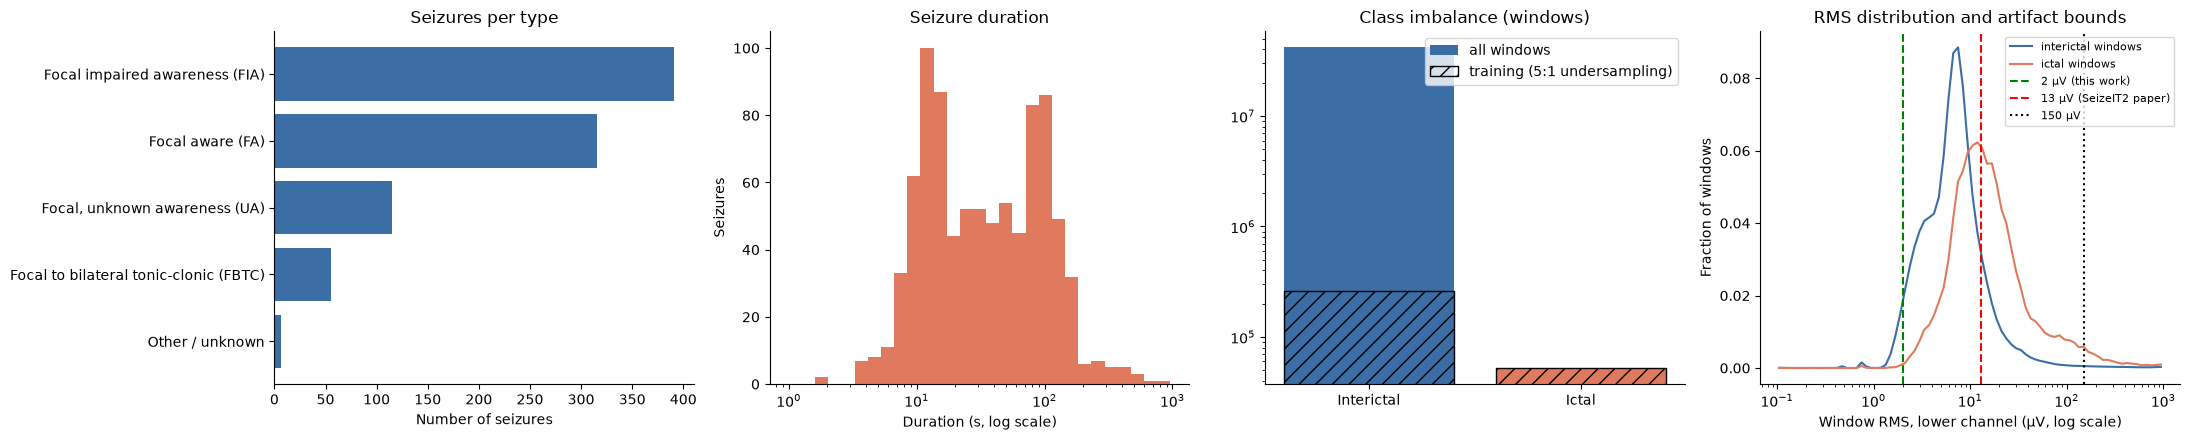

In [ ]:
# CELL 4b: Figure - dataset overview

fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
cnt = SEIZURES['group'].value_counts()
ax[0].barh(cnt.index[::-1], cnt.values[::-1], color='#3A6EA5')
ax[0].set_title('Seizures per type'); ax[0].set_xlabel('Number of seizures')
ax[1].hist(SEIZURES['duration'], bins=np.logspace(0, np.log10(max(SEIZURES.duration.max(), 10)), 30), color='#E07A5F')
ax[1].set_xscale('log'); ax[1].set_title('Seizure duration'); ax[1].set_xlabel('Duration (s, log scale)'); ax[1].set_ylabel('Seizures')
n_bal = UNDERSAMPLE_RATIO * n_ictal
ax[2].bar(['Interictal', 'Ictal'], [len(y_all) - n_ictal, n_ictal], color=['#3A6EA5', '#E07A5F'], label='all windows')
ax[2].bar(['Interictal', 'Ictal'], [n_bal, n_ictal], color='none', edgecolor='k', hatch='//', label=f'training ({UNDERSAMPLE_RATIO}:1 undersampling)')
ax[2].set_yscale('log'); ax[2].set_title('Class imbalance (windows)'); ax[2].legend()
c_ = np.sqrt(RMS_BINS[:-1] * RMS_BINS[1:])
ax[3].plot(c_, rms_hist[0] / rms_hist[0].sum(), c='#3A6EA5', label='interictal windows')
ax[3].plot(c_, rms_hist[1] / max(rms_hist[1].sum(), 1), c='#E07A5F', label='ictal windows')
ax[3].axvline(RMS_MIN_UV, c='green', ls='--', label=f'{RMS_MIN_UV:g} µV (this work)')
ax[3].axvline(13, c='red', ls='--', label='13 µV (SeizeIT2 paper)')
ax[3].axvline(RMS_MAX_UV, c='k', ls=':', label=f'{RMS_MAX_UV:g} µV')
ax[3].set_xscale('log'); ax[3].set_xlabel('Window RMS, lower channel (µV, log scale)'); ax[3].set_ylabel('Fraction of windows')
ax[3].set_title('RMS distribution and artifact bounds'); ax[3].legend(fontsize=8)
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'dataset_overview.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. From window probabilities to alarms, and how they are scored

The classifier outputs a seizure probability for every 2 s window. A wearable must turn this into **alarms**:

1. **Artifact suppression** – windows flagged by the label-blind RMS rule get probability 0.
2. **Window decision** – a window is classified as *seizure* when its probability ≥ θ (θ is chosen on training
   patients, Section 6).
3. **8-out-of-10 rule** – an alarm is raised only when at least 8 of the last 10 windows (10 s) are classified as
   seizure, as in the SeizeIT2 baseline (Bhagubai et al., 2025). Seizures last tens of seconds while isolated false
   positives last one or two windows, so this rule removes many false alarms. It uses only *past* windows, so the
   detector could run in real time.
4. **Events** – consecutive alarm windows form one alarm; alarms closer than 90 s are merged and alarms longer than
   5 min are split (SzCORE rules).

**Event-level scoring (SzCORE, any-overlap).** A seizure counts as **detected** when an alarm overlaps it,
with a tolerance of 30 s before the onset and 60 s after the end. Every alarm that does not overlap any (extended)
seizure is a **false alarm**. We report:

* **Sensitivity** = detected seizures / all seizures
* **False alarms per hour (FA/h)** = false alarms / recording hours (all hours, artifacts included)
* **Precision** = correct alarms / all alarms, and **F1**

**Window-level metrics** (sensitivity, specificity, accuracy, AUROC, AUPR) are reported as well.
Because >99 % of windows are interictal, *accuracy* and *specificity* are always close to 100 % — even a detector
that never fires would reach ≈99.5 % accuracy. They are therefore secondary; FA/h is the meaningful measure of
specificity for a seizure detector, and **AUPR** is the most informative window-level measure under heavy class
imbalance.

The next cell defines these functions and tests them on small hand-made examples.

In [ ]:

#CELL 5: Post-processing and scoring functions (+ unit tests)

from sklearn.metrics import roc_auc_score, average_precision_score


def k_of_n(b, k=ALARM_K, n=ALARM_N):
    # True where at least k of the last n binary decisions (including the current one) are True.
    c = np.concatenate([[0], np.cumsum(b, dtype=np.int64)])
    i = np.arange(1, len(b) + 1)
    return (c[i] - c[np.maximum(0, i - n)]) >= k


def alarm_events(alarm, t):
    # Binary alarm windows -> list of [start, end] alarm events (seconds).
    if not alarm.any():
        return np.empty((0, 2))
    d = np.diff(np.concatenate([[0], alarm.astype(np.int8), [0]]))
    st, en = np.where(d == 1)[0], np.where(d == -1)[0] - 1
    ev = [[t[a], t[b] + WINDOW_SEC] for a, b in zip(st, en)]
    merged = [ev[0]]
    for s, e in ev[1:]:
        if s - merged[-1][1] < MERGE_GAP_SEC:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    out = []
    for s, e in merged:
        while e - s > MAX_EVENT_SEC:
            out.append([s, s + MAX_EVENT_SEC]); s += MAX_EVENT_SEC
        out.append([s, e])
    return np.array(out)


def score_events(hyp, ref):
    # hyp: (n,2) alarms, ref: (m,2) seizures [onset, end]. Returns (detected flags per seizure, n false alarms).
    if len(ref) == 0:
        return np.zeros(0, bool), len(hyp)
    ext = ref + np.array([-TOL_BEFORE_SEC, TOL_AFTER_SEC])
    if len(hyp) == 0:
        return np.zeros(len(ref), bool), 0
    ov = (hyp[:, None, 0] < ext[None, :, 1]) & (hyp[:, None, 1] > ext[None, :, 0])   # (n, m)
    return ov.any(0), int((~ov.any(1)).sum())


class SubjectEval:
    # Holds what is needed to evaluate one subject quickly for many thresholds.
    def __init__(self, s):
        self.s = s
        sl_ = sl_of(s)
        self.y, self.valid = y_all[sl_], valid_all[sl_]
        self.t, self.f = t_all[sl_], file_all[sl_]
        self.hours = REC[s]['file_dur'].sum() / 3600
        ev = REC[s]['ev']
        self.files = []
        for fid in np.unique(self.f):
            w = np.flatnonzero(self.f == fid)
            idx = slice(w[0], w[-1] + 1)                               # windows of one recording are contiguous
            e = ev[ev.file == fid]
            ref = np.c_[e.onset.values, e.onset.values + e.duration.values] if len(e) else np.empty((0, 2))
            self.files.append((idx, ref, e.index.values))
        self.n_sz = len(ev)

    def system_prob(self, p_raw):
        # artifact suppression: flagged windows cannot raise an alarm
        return np.where(self.valid, p_raw, 0.0)

    def alarm(self, p, thr):
        # per-window alarm state: >= ALARM_K of the last ALARM_N windows above threshold (per recording)
        out = np.zeros(len(p), bool)
        for idx, _, _ in self.files:
            out[idx] = k_of_n(p[idx] >= thr)
        return out

    def events(self, p_s, thr):
        det = np.zeros(self.n_sz, bool); n_fp = n_hyp = 0
        for idx, ref, ev_idx in self.files:
            hyp = alarm_events(k_of_n(p_s[idx] >= thr), self.t[idx])
            d, fp = score_events(hyp, ref)
            det[ev_idx] = d; n_fp += fp; n_hyp += len(hyp)
        return det, n_fp, n_hyp


def sweep(evals, probs, thresholds):
    # Pooled event sensitivity and FA/h for every threshold.
    n_sz = sum(e.n_sz for e in evals); hours = sum(e.hours for e in evals)
    sens, fah = [], []
    for thr in thresholds:
        tp = fp = 0
        for e in evals:
            d, f, _ = e.events(probs[e.s], thr); tp += d.sum(); fp += f
        sens.append(tp / max(n_sz, 1)); fah.append(fp / max(hours, 1e-9))
    return np.array(sens), np.array(fah)


def pick_threshold(sens, fah, thresholds, fa_target=FA_TARGET_PER_H):
    # Highest sensitivity with FA/h <= target; if impossible, a penalised score.
    ok = fah <= fa_target
    if ok.any():
        best = np.flatnonzero(ok)[np.lexsort((fah[ok], -sens[ok]))[0]]
        return thresholds[best], sens[best]
    best = int(np.argmin(fah - 1e-3 * sens))
    return thresholds[best], sens[best] * fa_target / fah[best]


def window_metrics(y, alarm, p):
    tp = int(((alarm == 1) & (y == 1)).sum()); fn = int(((alarm == 0) & (y == 1)).sum())
    tn = int(((alarm == 0) & (y == 0)).sum()); fp = int(((alarm == 1) & (y == 0)).sum())
    both = 0 < y.sum() < len(y)
    return dict(win_sens=tp / max(tp + fn, 1), win_spec=tn / max(tn + fp, 1),
                win_acc=(tp + tn) / max(len(y), 1),
                auroc=roc_auc_score(y, p) if both else np.nan,
                aupr=average_precision_score(y, p) if both else np.nan,
                win_tp=tp, win_fn=fn, win_tn=tn, win_fp=fp)


# ---------------- unit tests ----------------
assert not k_of_n(np.array([1, 1, 1, 1, 1, 1, 1, 0, 0, 0], bool)).any()             # 7 of 10 -> no alarm
assert k_of_n(np.array([1, 1, 0, 1, 1, 1, 1, 1, 1, 0], bool))[-2]                    # 8 of last 10 -> alarm
_t = np.arange(1000, dtype=float)
_a = np.zeros(1000, bool); _a[100:110] = True; _a[150:160] = True; _a[500:505] = True
_h = alarm_events(_a, _t)
assert len(_h) == 2 and _h[0, 0] == 100 and _h[0, 1] == 161, _h          # gap 40 s < 90 s -> merged
_det, _fp = score_events(_h, np.array([[120., 140.], [700., 720.]]))
assert list(_det) == [True, False] and _fp == 1                          # 2nd alarm is a false alarm
_det, _fp = score_events(np.array([[730., 735.]]), np.array([[600., 700.]]))
assert _det[0] and _fp == 0                                               # within 60 s after the end -> detected
_det, _fp = score_events(np.array([[540., 560.]]), np.array([[600., 700.]]))
assert not _det[0] and _fp == 1                                           # 40 s before onset -> too early
_a = np.zeros(1000, bool); _a[0:700] = True
assert len(alarm_events(_a, _t)) == 3                                     # 701 s alarm split into 300+300+101 s
print('Post-processing and scoring functions OK (all unit tests passed)')

Post-processing and scoring functions OK (all unit tests passed)


## 6. Nested patient-wise cross-validation with Optuna

**Patient-wise folds.** The detector will be used on *new* patients, so the data are split **by patient**:
the 125 patients are divided randomly into `N_OUTER_FOLDS` = 10 groups. Each group is the test set once, and the
model for that fold never sees any data of those patients. Every patient is therefore tested exactly once by a
model that was trained without them – the same principle as leave-one-subject-out (LOSO), but ~10× faster, which
matters for >11,000 hours of recordings. (Setting `N_OUTER_FOLDS` to the number of patients gives exact LOSO.)
Splitting windows at random instead would leak information: windows of one patient are strongly correlated and
even overlap by 50 %.

**Why nested?** Hyper-parameters (with Optuna) and the threshold are chosen **inside** every fold using only the
training patients. If they were chosen by looking at the test results, the reported performance would be too
optimistic (over-fitting to the test set).

```
for each outer fold (10 groups of test patients):
    training patients = all other patients
    split training patients 80 % / 20 % BY PATIENT          (inner split)
    Optuna, N trials:
        train XGBoost on the 80 %
        score = AUPR on the 20 % validation patients
    with the best settings: threshold = highest seizure sensitivity
                            with <= FA_TARGET_PER_H false alarms / hour on the validation patients
    final model <- best settings, trained on ALL training patients
    evaluate ONCE on the test patients   (never used for any choice)
```

**How over-fitting is avoided**

1. Test patients are never used for training, tuning or the threshold.
2. The Optuna validation set consists of *other patients* (not other windows of the same patients).
3. The search space only contains simple, regularised models (shallow trees, minimum leaf size, subsampling).
4. **AUPR** (area under the precision–recall curve) is the tuning objective: it measures how well seizure windows
   are ranked above interictal windows and, unlike accuracy, is meaningful when only ~0.1 % of windows are ictal.
   To keep each trial fast it is computed on all seizure windows plus a fixed random sample of
   `OPTUNA_VAL_BACKGROUND` interictal windows of the validation patients (the same sample for every trial, so the
   comparison between trials is fair).
5. **Over-fitting check** (Section 7): performance on training data, on validation patients and on test patients
   are compared.

**Fixed vs tuned threshold.** The SeizeIT2 baseline uses a fixed threshold of 0.5. After 5:1 undersampling the
predicted probabilities are shifted upwards, so 0.5 has no special meaning; we therefore also choose the threshold
on the training patients. Both are evaluated on the same models and test patients (Section 7), so the effect of
this choice can be seen directly. RQ1/RQ2 use the tuned threshold.

**Temporal context features.** A single 2 s window says little about whether the signal has *changed*. A seizure
is a change compared with the recent background, so for every one of the 42 features we add its difference from
its mean over the previous `CONTEXT_SEC` = 60 s of the same recording (artifact-free windows only, past only, so
it could run in real time). The model therefore sees 84 features: 42 "now" + 42 "change". They are computed from
the stored features when the data are used, so the feature extraction (Cell 3) is unchanged. Setting
`CONTEXT_SEC = 0` reproduces the 42-feature baseline.

**Class imbalance.** The training set keeps all ictal windows and a random 5× larger sample of artifact-free
interictal windows. Undersampling shifts the probabilities upwards; this is why the threshold is chosen on the
*complete* recordings of the validation patients (real class ratio) instead of using 0.5.

**Operating points.** `FA_TARGET_PER_H` = 1 false alarm per hour defines the **main result** (fixed before the
analysis). Because the threshold is the only thing that changes, the same models are also evaluated at 2 and 3 false
alarms per hour (`EXTRA_FA_TARGETS`, thresholds again chosen on the validation patients) and at the fixed threshold
0.5 of the SeizeIT2 baseline. This shows the trade-off between sensitivity and false alarms without retraining.

Every finished fold is saved in `results/loso_folds/`; re-running the cell skips finished folds.

In [ ]:
# CELL 6: Nested patient-wise CV with Optuna (long; resumable)

import joblib, optuna
from xgboost import XGBClassifier
optuna.logging.set_verbosity(optuna.logging.WARNING)

EVALS   = {s: SubjectEval(s) for s in SUBJECTS}
POS_IDX = np.flatnonzero(y_all == 1).astype(np.int32)                 # all seizure windows
NEG_IDX = np.flatnonzero((y_all == 0) & valid_all).astype(np.int32)   # artifact-free background windows

# patient-wise folds (fixed by the random seed, so a restart gives the same folds)
_perm = np.random.default_rng(RANDOM_SEED).permutation(len(SUBJECTS))
FOLDS = [sorted(SUBJECTS[i] for i in part) for part in np.array_split(_perm, min(N_OUTER_FOLDS, len(SUBJECTS)))]
pd.Series({f'fold {k}': ', '.join(f_) for k, f_ in enumerate(FOLDS)}).to_csv(RESULTS_DIR / 'folds.csv')


def rows_of(subjects, idx_pool):
    ids = [SUBJECTS.index(s) for s in subjects]
    return idx_pool[np.isin(subj_all[idx_pool], ids)]


MODEL_FEATURE_NAMES = FEATURE_NAMES + ([f'{n}_d{CONTEXT_SEC}s' for n in FEATURE_NAMES] if CONTEXT_SEC > 0 else [])


def context_diff(X, valid, f):
    # Each feature minus its mean over the previous CONTEXT_SEC seconds (causal, same recording,
    # artifact-free windows only). Shows how the signal CHANGES compared with the recent past.
    k   = int(CONTEXT_SEC / STEP_SEC)
    out = np.empty_like(X)
    edges = np.flatnonzero(np.diff(f)) + 1
    for a, b in zip(np.r_[0, edges], np.r_[edges, len(f)]):              # one recording at a time
        Xi = X[a:b].astype(np.float64)
        ok = np.isfinite(Xi) & valid[a:b, None]
        S  = np.vstack([np.zeros((1, X.shape[1])), np.cumsum(np.where(ok, Xi, 0.0), axis=0)])
        C  = np.vstack([np.zeros((1, X.shape[1])), np.cumsum(ok, axis=0)])
        i  = np.arange(b - a); lo = np.maximum(0, i - k)
        cnt  = C[i] - C[lo]                                                # previous k windows (not the current one)
        mean = np.where(cnt > 0, (S[i] - S[lo]) / np.maximum(cnt, 1), Xi)
        out[a:b] = (Xi - mean).astype(np.float32)
    return out


def subject_features(s):
    # All model features of one patient: the 42 stored features (+ 42 context features).
    sl_ = sl_of(s)
    X = np.asarray(X_all[sl_], dtype=np.float32)
    if CONTEXT_SEC <= 0:
        return X
    return np.hstack([X, context_diff(X, valid_all[sl_], file_all[sl_])])


def rows_to_X(idx):
    # Model features for the given (sorted) global row indices, built patient by patient.
    parts, subj_of_rows = [], subj_all[idx]
    for si in np.unique(subj_of_rows):
        local = idx[subj_of_rows == si] - OFF[si]
        parts.append(subject_features(SUBJECTS[si])[local])
    return np.vstack(parts) if parts else np.empty((0, len(MODEL_FEATURE_NAMES)), np.float32)


def training_set(train_subjects, seed=RANDOM_SEED):
    # All ictal windows + random 5x more artifact-free interictal windows of the given patients.
    rng = np.random.default_rng(seed)
    pos = rows_of(train_subjects, POS_IDX)
    neg = rows_of(train_subjects, NEG_IDX)
    neg = rng.choice(neg, min(len(neg), UNDERSAMPLE_RATIO * len(pos)), replace=False)
    idx = np.sort(np.concatenate([pos, neg]))
    return rows_to_X(idx), y_all[idx]


def predict_subject(model, s):
    return model.predict_proba(subject_features(s))[:, 1]


def op_metrics(e, p, thr, prefix):
    # Event- and window-level counts of one patient for one threshold (an 'operating point').
    det_, fp_, al_ = e.events(p, thr)
    a_ = e.alarm(p, thr)
    return {f'{prefix}_threshold': float(thr), f'{prefix}_detected': int(det_.sum()),
            f'{prefix}_false_alarms': int(fp_), f'{prefix}_alarms': int(al_),
            f'{prefix}_win_tp': int((a_ & (e.y == 1)).sum()), f'{prefix}_win_fn': int((~a_ & (e.y == 1)).sum()),
            f'{prefix}_win_tn': int((~a_ & (e.y == 0)).sum()), f'{prefix}_win_fp': int((a_ & (e.y == 0)).sum())}


def run_outer_fold(k):
    t0 = time.time()
    test_s  = FOLDS[k]
    train_s = [s for s in SUBJECTS if s not in test_s]

    # inner split of the TRAINING patients (by patient) 
    rng   = np.random.default_rng(RANDOM_SEED + k)
    val_s = sorted(rng.choice(train_s, max(1, round(INNER_VAL_FRACTION * len(train_s))), replace=False).tolist())
    fit_s = [s for s in train_s if s not in val_s]
    X_fit, y_fit = training_set(fit_s)

    # Optuna validation rows: all ictal windows + a fixed random sample of background windows (real recordings)
    vpos = rows_of(val_s, np.flatnonzero(y_all == 1))
    vneg = rows_of(val_s, np.flatnonzero(y_all == 0))
    n_neg_all = len(vneg)
    vneg = rng.choice(vneg, min(len(vneg), OPTUNA_VAL_BACKGROUND), replace=False)
    vidx = np.sort(np.concatenate([vpos, vneg]))
    X_v, y_v = rows_to_X(vidx), y_all[vidx]
    v_ok = valid_all[vidx]
    w_v  = np.where(y_v == 1, 1.0, n_neg_all / max(len(vneg), 1))   # weights -> AUPR as on the full recordings

    def objective(trial):
        m = XGBClassifier(**suggest_xgb_params(trial), **XGB_FIXED).fit(X_fit, y_fit)
        p = np.where(v_ok, m.predict_proba(X_v)[:, 1], 0.0)      # artifacts cannot raise an alarm
        return average_precision_score(y_v, p, sample_weight=w_v)
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    study.enqueue_trial(DEFAULT_PARAMS)
    study.optimize(objective, n_trials=N_OPTUNA_TRIALS)
    best = study.best_params
    del X_v

    # threshold on the COMPLETE recordings of the validation patients 
    model_a = XGBClassifier(**best, **XGB_FIXED).fit(X_fit, y_fit)
    del X_fit
    probs = {s: EVALS[s].system_prob(predict_subject(model_a, s)) for s in val_s}
    sens_v, fah_v = sweep([EVALS[s] for s in val_s], probs, THRESHOLD_GRID)
    thr, _ = pick_threshold(sens_v, fah_v, THRESHOLD_GRID)
    iv = int(np.flatnonzero(THRESHOLD_GRID == thr)[0])
    thr_extra = {t: float(pick_threshold(sens_v, fah_v, THRESHOLD_GRID, fa_target=t)[0]) for t in EXTRA_FA_TARGETS}
    del probs

    # final model on ALL training patients, evaluated once on the test patients 
    X_tr, y_tr = training_set(train_s)
    model = XGBClassifier(**best, **XGB_FIXED).fit(X_tr, y_tr)
    train_auroc = roc_auc_score(y_tr, model.predict_proba(X_tr)[:, 1])
    del X_tr

    results, seizures = [], []
    for s in test_s:
        e   = EVALS[s]
        raw = predict_subject(model, s)
        p   = e.system_prob(raw)
        det, n_fp, n_alarms = e.events(p, thr)
        wm  = window_metrics(e.y, e.alarm(p, thr).astype(int), p)
        # model AUROC on the same kind of windows as in training (all ictal + artifact-free interictal windows)
        m_  = (e.y == 1) | e.valid
        model_auroc = roc_auc_score(e.y[m_], raw[m_]) if 0 < e.y[m_].sum() < m_.sum() else np.nan
        ev  = REC[s]['ev']
        seizures += [dict(subject=s, type=t, group=seizure_group(t), duration=float(d), detected=bool(x))
                     for t, d, x in zip(ev['type'], ev['duration'], det)]
        results.append(dict(subject=s, fold=k, n_seizures=e.n_sz, n_detected=int(det.sum()),
                            sensitivity=det.mean() if e.n_sz else np.nan,
                            n_false_alarms=n_fp, n_alarms=n_alarms, hours=e.hours, fa_per_hour=n_fp / e.hours,
                            precision=(n_alarms - n_fp) / n_alarms if n_alarms else np.nan,
                            **wm, model_auroc=model_auroc, train_auroc=train_auroc, val_aupr=study.best_value, threshold=thr,
                            val_sens=float(sens_v[iv]), val_fah=float(fah_v[iv]),
                            **op_metrics(e, p, PAPER_THRESHOLD, 'p05'),                    # paper: fixed 0.5
                            **{kk: vv for t in EXTRA_FA_TARGETS
                               for kk, vv in op_metrics(e, p, thr_extra[t], f'fa{t:g}').items()}))
        np.savez_compressed(FOLD_DIR / f'{s}_prob.npz', p_raw=raw.astype(np.float32), p_sys=p.astype(np.float32))
    joblib.dump(dict(results=results, seizures=seizures, params=best, fold_min=(time.time() - t0) / 60,
                     importance=model.get_booster().get_score(importance_type='gain')),
                FOLD_DIR / f'fold_{k:02d}.pkl')
    return results, (time.time() - t0) / 60


print(f'{len(MODEL_FEATURE_NAMES)} features per window (context {CONTEXT_SEC} s)')
print(f'Nested patient-wise CV: {len(FOLDS)} folds ({len(SUBJECTS)} patients) | {N_OPTUNA_TRIALS} Optuna trials '
      f'per fold | FA target {FA_TARGET_PER_H}/h (extra: {EXTRA_FA_TARGETS}) | alarm rule {ALARM_K}/{ALARM_N}')
t_start, n_new = time.time(), 0
for k in range(len(FOLDS)):
    if (FOLD_DIR / f'fold_{k:02d}.pkl').exists():
        continue
    res_k, mins = run_outer_fold(k); n_new += 1
    r = pd.DataFrame(res_k)
    left = sum(not (FOLD_DIR / f'fold_{j:02d}.pkl').exists() for j in range(len(FOLDS)))
    print(f'[fold {k + 1}/{len(FOLDS)}] {len(r)} test patients: detected {r.n_detected.sum()}/{r.n_seizures.sum()}, '
          f'{r.n_false_alarms.sum()} false alarms in {r.hours.sum():.0f} h ({r.n_false_alarms.sum() / r.hours.sum():.2f}/h), '
          f'window sens {r.win_tp.sum() / max(r.win_tp.sum() + r.win_fn.sum(), 1):.3f} '
          f'spec {r.win_tn.sum() / max(r.win_tn.sum() + r.win_fp.sum(), 1):.4f}, '
          f'AUROC train {r.train_auroc.iloc[0]:.3f} / test {r.model_auroc.mean():.3f}, thr {r.threshold.iloc[0]:.3f} | '
          f'{mins:.0f} min, ETA {(time.time() - t_start) / n_new * left / 60:.0f} min')
print('All folds finished.')

84 features per window (context 60 s)
Nested patient-wise CV: 10 folds (125 patients) | 15 Optuna trials per fold | FA target 1.0/h (extra: [2.0, 3.0]) | alarm rule 8/10
All folds finished.


## 7. Overall results

Two ways of summarising are shown:

* **Pooled** – all seizures and all hours of all patients together (each seizure counts equally). This is the
  usual way results on SeizeIT2 and in SzCORE are reported.
* **Per patient** – metric computed per patient, then mean ± SD and median (each patient counts equally).
  Patients differ a lot, so the spread is part of the result.

**Uncertainty.** Seizures of the same patient are not independent (one patient contributes up to 75 seizures), so
95 % confidence intervals are obtained with a **patient-level bootstrap**: patients are resampled with replacement
(`BOOT_B` = 2000 times) and the pooled metric is recomputed. Intervals that treat seizures as independent (e.g. the
Wilson interval) would be too narrow.

At the end, an **over-fitting check** compares performance on the training data with performance on the unseen test patients.

In [ ]:
# CELL 7: Overall results


def boot_ratio(num, den, B=BOOT_B, seed=RANDOM_SEED):
    # 95 % CI of sum(num)/sum(den) by resampling PATIENTS (the independent units) with replacement.
    num, den = np.asarray(num, float), np.asarray(den, float)
    if len(num) == 0: return (np.nan, np.nan)
    idx = np.random.default_rng(seed).integers(0, len(num), (B, len(num)))
    r = num[idx].sum(1) / np.maximum(den[idx].sum(1), 1e-12)
    return tuple(np.percentile(r, [2.5, 97.5]))


def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

folds = [joblib.load(FOLD_DIR / f'fold_{k:02d}.pkl') for k in range(len(FOLDS)) if (FOLD_DIR / f'fold_{k:02d}.pkl').exists()]
RES = pd.DataFrame([r for f in folds for r in f['results']])
SZ  = pd.DataFrame([x for f in folds for x in f['seizures']])
RES.to_csv(RESULTS_DIR / 'per_subject_results.csv', index=False)
SZ.to_csv(RESULTS_DIR / 'per_seizure_results.csv', index=False)

tp, n_sz = int(SZ.detected.sum()), len(SZ)
fa, hrs  = int(RES.n_false_alarms.sum()), RES.hours.sum()
n_al     = int(RES.n_alarms.sum())
lo, hi   = boot_ratio(RES.n_detected, RES.n_seizures)          # patient-level bootstrap
flo, fhi = boot_ratio(RES.n_false_alarms, RES.hours)
prec     = (n_al - fa) / n_al if n_al else np.nan
sens     = tp / n_sz
wtp, wfn, wtn, wfp = (int(RES[c].sum()) for c in ['win_tp', 'win_fn', 'win_tn', 'win_fp'])

pooled = {
    'Subjects evaluated'            : f'{len(RES)}',
    'Recording time'                : f'{hrs:,.1f} h',
    'Seizures detected'             : f'{tp} / {n_sz}',
    'Event sensitivity (pooled)'    : f'{sens:.3f}  [95% CI {lo:.3f}-{hi:.3f}]',
    'False alarms per hour (pooled)': f'{fa / hrs:.2f}  [95% CI {flo:.2f}-{fhi:.2f}]  ({fa} false alarms, {24 * fa / hrs:.1f} per day)',
    'Event precision / F1'          : f'{prec:.3f} / {2 * prec * sens / (prec + sens):.3f}',
    'Window sensitivity'            : f'{wtp / (wtp + wfn):.3f}',
    'Window specificity'            : f'{wtn / (wtn + wfp):.4f}',
    'Window accuracy'               : f'{(wtp + wtn) / (wtp + wtn + wfp + wfn):.4f}',
}
print('POOLED RESULTS (nested patient-wise cross-validation; 95 % CI = patient-level bootstrap)'); print('-' * 70)
for k_, v_ in pooled.items(): print(f'  {k_:32s}: {v_}')

cols = ['sensitivity', 'fa_per_hour', 'precision', 'win_sens', 'win_spec', 'win_acc', 'auroc', 'model_auroc', 'aupr']
summ = RES[cols].agg(['mean', 'std', 'median', 'min', 'max']).T
summ.index = ['Event sensitivity', 'FA / hour', 'Event precision', 'Window sensitivity', 'Window specificity',
              'Window accuracy', 'AUROC (system)', 'AUROC (model)', 'AUPR']
print('\nPER-SUBJECT RESULTS'); display(summ.round(3))
pd.Series(pooled).to_csv(RESULTS_DIR / 'pooled_results.csv')
summ.to_csv(RESULTS_DIR / 'per_subject_summary.csv')

#  comparison with the fixed threshold of the paper 
def summary_row(det, fa_, nal, tp_, fn_, tn_, fp_):
    pr = (nal - fa_) / nal if nal else np.nan
    return {'Event sensitivity': det / n_sz, 'FA / hour': fa_ / hrs, 'FA / day': 24 * fa_ / hrs,
            'Event precision': pr, 'Window sensitivity': tp_ / (tp_ + fn_), 'Window specificity': tn_ / (tn_ + fp_),
            'Window accuracy': (tp_ + tn_) / (tp_ + tn_ + fp_ + fn_)}
def op_row(prefix):
    g = lambda c: RES[f'{prefix}_{c}'].sum()
    return summary_row(g('detected'), g('false_alarms'), g('alarms'), g('win_tp'), g('win_fn'), g('win_tn'), g('win_fp'))
COMP = pd.DataFrame({
    'Never alarm (trivial baseline)': summary_row(0, 0, 0, 0, wtp + wfn, wtn + wfp, 0),
    f'Fixed threshold {PAPER_THRESHOLD} (paper)': op_row('p05'),
    f'FA target {FA_TARGET_PER_H:g}/h (MAIN)': summary_row(tp, fa, n_al, wtp, wfn, wtn, wfp),
    **{f'FA target {t:g}/h': op_row(f'fa{t:g}') for t in EXTRA_FA_TARGETS}})
print('\nOPERATING POINTS (same models, same test patients; thresholds chosen on training patients)')
print('The trivial detector that never raises an alarm reaches a window accuracy of '
      f'{(wtn + wfp) / (wtp + wfn + wtn + wfp):.4f} with 0 % sensitivity: accuracy alone is not informative here.')
display(COMP.round(4))
COMP.to_csv(RESULTS_DIR / 'threshold_comparison.csv')

print(f'\nThreshold chosen per fold: median {RES.threshold.median():.3f} '
      f'(range {RES.threshold.min():.3f}-{RES.threshold.max():.3f})')


# over-fitting check 
print('\nOVER-FITTING CHECK'); print('-' * 70)
tr_auc = RES.groupby('fold').train_auroc.first().mean()
print(f'  Model AUROC on training data      : {tr_auc:.3f}')
print(f'  Model AUROC on test patients      : {RES.model_auroc.mean():.3f}   (gap {tr_auc - RES.model_auroc.mean():+.3f})')
print('    (both on ictal + artifact-free interictal windows, so they are directly comparable)')
print(f'  AUPR on validation patients (Optuna best): {RES.groupby("fold").val_aupr.first().mean():.3f}')
print(f'  AUPR on test patients                    : {RES.aupr.mean():.3f}')
print(f'  Threshold-selection patients: sensitivity {RES.groupby("fold").val_sens.first().mean():.3f}, '
      f'FA/h {RES.groupby("fold").val_fah.first().mean():.2f}')
print(f'  Test patients (pooled)      : sensitivity {sens:.3f}, FA/h {fa / hrs:.2f}')
print('  A small gap means the model generalises to new patients. A large gap (e.g. > 0.1 AUROC) would mean\n'
      '  over-fitting: then restrict the search space in Cell 1 (smaller max_depth, larger min_child_weight).')

POOLED RESULTS (nested patient-wise cross-validation; 95 % CI = patient-level bootstrap)
----------------------------------------------------------------------
  Subjects evaluated              : 125
  Recording time                  : 11,626.2 h
  Seizures detected               : 494 / 883
  Event sensitivity (pooled)      : 0.559  [95% CI 0.443-0.686]
  False alarms per hour (pooled)  : 0.93  [95% CI 0.79-1.07]  (10790 false alarms, 22.3 per day)
  Event precision / F1            : 0.044 / 0.082
  Window sensitivity              : 0.318
  Window specificity              : 0.9951
  Window accuracy                 : 0.9943

PER-SUBJECT RESULTS


,mean,std,median,min,max
Event sensitivity,0.680,0.361,0.800,0.000,1.000
FA / hour,0.940,0.788,0.714,0.000,3.646
Event precision,0.082,0.159,0.034,0.000,1.000
Window sensitivity,0.304,0.258,0.244,0.000,0.900
Window specificity,0.995,0.004,0.997,0.982,1.000
Window accuracy,0.993,0.012,0.995,0.879,1.000
AUROC (system),0.775,0.190,0.819,0.157,0.998
AUROC (model),0.894,0.121,0.926,0.358,1.000
AUPR,0.140,0.183,0.067,0.000,0.835



OPERATING POINTS (same models, same test patients; thresholds chosen on training patients)
The trivial detector that never raises an alarm reaches a window accuracy of 0.9987 with 0 % sensitivity: accuracy alone is not informative here.


,Never alarm (trivial baseline),Fixed threshold 0.5 (paper),FA target 1/h (MAIN),FA target 2/h,FA target 3/h
Event sensitivity,0.0000,0.5764,0.5595,0.6942,0.7758
FA / hour,0.0000,0.9872,0.9281,1.9439,2.9055
FA / day,0.0000,23.6919,22.2737,46.6531,69.7319
Event precision,NaN,0.0429,0.0441,0.0265,0.0198
Window sensitivity,0.0000,0.3290,0.3184,0.3956,0.4526
Window specificity,1.0000,0.9948,0.9951,0.9884,0.9803
Window accuracy,0.9987,0.9940,0.9943,0.9877,0.9797



Threshold chosen per fold: median 0.525 (range 0.400-0.600)

OVER-FITTING CHECK
----------------------------------------------------------------------
  Model AUROC on training data      : 0.969
  Model AUROC on test patients      : 0.894   (gap +0.075)
    (both on ictal + artifact-free interictal windows, so they are directly comparable)
  AUPR on validation patients (Optuna best): 0.087
  AUPR on test patients                    : 0.140
  Threshold-selection patients: sensitivity 0.586, FA/h 0.94
  Test patients (pooled)      : sensitivity 0.559, FA/h 0.93
  A small gap means the model generalises to new patients. A large gap (e.g. > 0.1 AUROC) would mean
  over-fitting: then restrict the search space in Cell 1 (smaller max_depth, larger min_child_weight).


## 8. RQ1 – Sensitivity by seizure type

Each seizure is assigned to a clinical type from its `eventType` code. Sensitivity is the fraction of seizures of
that type that were detected, with a 95 % patient-level bootstrap confidence interval. Non-overlapping intervals
indicate a real difference; types with few seizures (or seizures from few patients) have wide intervals.

In [ ]:
# CELL 8: RQ1 - sensitivity by seizure type

def rate_table(df, by, order=None):
    g = df.groupby(by, observed=True)['detected'].agg(['sum', 'count']).rename(columns={'sum': 'detected', 'count': 'n'})
    if order is not None: g = g.reindex([o for o in order if o in g.index])
    g['sensitivity'] = g.detected / g.n
    ci = []
    for key in g.index:                                    # patient-level bootstrap within each group
        per = df[df[by] == key].groupby('subject')['detected'].agg(['sum', 'count'])
        ci.append(boot_ratio(per['sum'], per['count']))
    g['ci_low'], g['ci_high'] = [c[0] for c in ci], [c[1] for c in ci]
    g['subjects'] = df.groupby(by, observed=True)['subject'].nunique().reindex(g.index)
    return g

RQ1 = rate_table(SZ, 'group')
RQ1.to_csv(RESULTS_DIR / 'rq1_by_type.csv')
display(RQ1.round(3))

,detected,n,sensitivity,ci_low,ci_high,subjects
group,,,,,,
Focal aware (FA),149,316,0.472,0.212,0.727,34
Focal impaired awareness (FIA),240,391,0.614,0.459,0.771,74
Focal to bilateral tonic-clonic (FBTC),54,55,0.982,0.939,1.000,37
"Focal, unknown awareness (UA)",51,115,0.443,0.376,0.557,26
Other / unknown,0,6,0.000,0.000,0.000,2


## 9. RQ2 – Sensitivity by seizure duration

Duration is the annotated duration from the `_events.tsv` file (not estimated from windows).

In [ ]:
# CELL 9: RQ2 - sensitivity by seizure duration

DUR_BINS   = [0, 30, 60, 120, np.inf]
DUR_LABELS = ['<=30 s', '31-60 s', '61-120 s', '>120 s']
SZ['dur_bin'] = pd.cut(SZ.duration, DUR_BINS, labels=DUR_LABELS, right=True)
RQ2 = rate_table(SZ, 'dur_bin', DUR_LABELS)
RQ2.to_csv(RESULTS_DIR / 'rq2_by_duration.csv')
display(RQ2.round(3))
print(f'Median duration: detected seizures {SZ.duration[SZ.detected].median():.0f} s, '
      f'missed seizures {SZ.duration[~SZ.detected].median():.0f} s')

,detected,n,sensitivity,ci_low,ci_high,subjects
dur_bin,,,,,,
<=30 s,138,427,0.323,0.226,0.457,53
31-60 s,92,142,0.648,0.532,0.762,61
61-120 s,185,220,0.841,0.716,0.920,68
>120 s,79,94,0.840,0.753,0.917,48


Median duration: detected seizures 66 s, missed seizures 14 s


## 9b. Does the temporal context help? (McNemar test)

The 42-feature model (run with `CONTEXT_SEC = 0`, saved in `results_baseline/`) and the 84-feature model are
evaluated on exactly the same seizures, at the same operating point (1 false alarm/h). The **McNemar test** uses
only the seizures on which the two models disagree (exact binomial version). Because seizures of one patient are not
independent, the comparison is also made with **patients as units**: a patient-level bootstrap CI of the difference
in sensitivity and a Wilcoxon signed-rank test on the per-patient sensitivities.

In [ ]:
# CELL 9b: McNemar test - baseline (42 features) vs. temporal context (84 features)

from scipy.stats import binomtest

base_csv = BASELINE_RESULTS_DIR / 'per_seizure_results.csv'
if not base_csv.exists() or BASELINE_RESULTS_DIR.resolve() == RESULTS_DIR.resolve():
    print(f'No baseline results found in {BASELINE_RESULTS_DIR} - skipped.')
else:
    base = pd.read_csv(base_csv)
    cur  = SZ.copy()
    for d in (base, cur):
        d['k'] = d.groupby('subject').cumcount()                 # seizure number within each patient
    m = base.merge(cur, on=['subject', 'k'], suffixes=('_base', '_new'))
    assert len(m) == len(base) == len(cur) and np.allclose(m.duration_base, m.duration_new), 'seizure lists differ'
    db, dn = m.detected_base.astype(bool), m.detected_new.astype(bool)
    n_both, n_new, n_base, n_none = (db & dn).sum(), (~db & dn).sum(), (db & ~dn).sum(), (~db & ~dn).sum()
    p = binomtest(int(min(n_new, n_base)), int(n_new + n_base), 0.5).pvalue
    MCN = pd.DataFrame({'detected': [n_both, n_new, n_base, n_none]},
                       index=['by both models', 'only with temporal context', 'only by baseline', 'by neither'])
    display(MCN)
    print(f'Sensitivity: baseline {db.mean():.3f} -> context {dn.mean():.3f}')
    print(f'McNemar exact test (seizures as units): p = {p:.4g}')

    # Patient-level analyses (patients are the independent units)
    from scipy.stats import wilcoxon
    per = m.assign(b=db, n=dn).groupby('subject').agg(b=('b', 'sum'), n=('n', 'sum'), k=('b', 'size'))
    lo_d, hi_d = boot_ratio(per.n - per.b, per.k)
    diff_p = (per.n - per.b) / per.k
    w = wilcoxon(diff_p[diff_p != 0]) if (diff_p != 0).sum() > 0 else None
    print(f'Difference in pooled sensitivity: {(per.n - per.b).sum() / per.k.sum():+.3f} '
          f'[95 % CI {lo_d:+.3f} to {hi_d:+.3f}, patient-level bootstrap]')
    print(f'Patients improved / worse / unchanged: {(diff_p > 0).sum()} / {(diff_p < 0).sum()} / {(diff_p == 0).sum()}'
          + (f'; Wilcoxon signed-rank on per-patient sensitivity: p = {w.pvalue:.4g}' if w is not None else ''))
    print('The McNemar test treats seizures as independent; the bootstrap CI and the Wilcoxon test use patients as units.')
    MCN.to_csv(RESULTS_DIR / 'mcnemar_baseline_vs_context.csv')

,detected
by both models,416
only with temporal context,78
only by baseline,46
by neither,343


Sensitivity: baseline 0.523 -> context 0.559
McNemar exact test (seizures as units): p = 0.005161
Difference in pooled sensitivity: +0.036 [95 % CI -0.002 to +0.077, patient-level bootstrap]
Patients improved / worse / unchanged: 24 / 12 / 89; Wilcoxon signed-rank on per-patient sensitivity: p = 0.04259
The McNemar test treats seizures as independent; the bootstrap CI and the Wilcoxon test use patients as units.


## 10. Figures

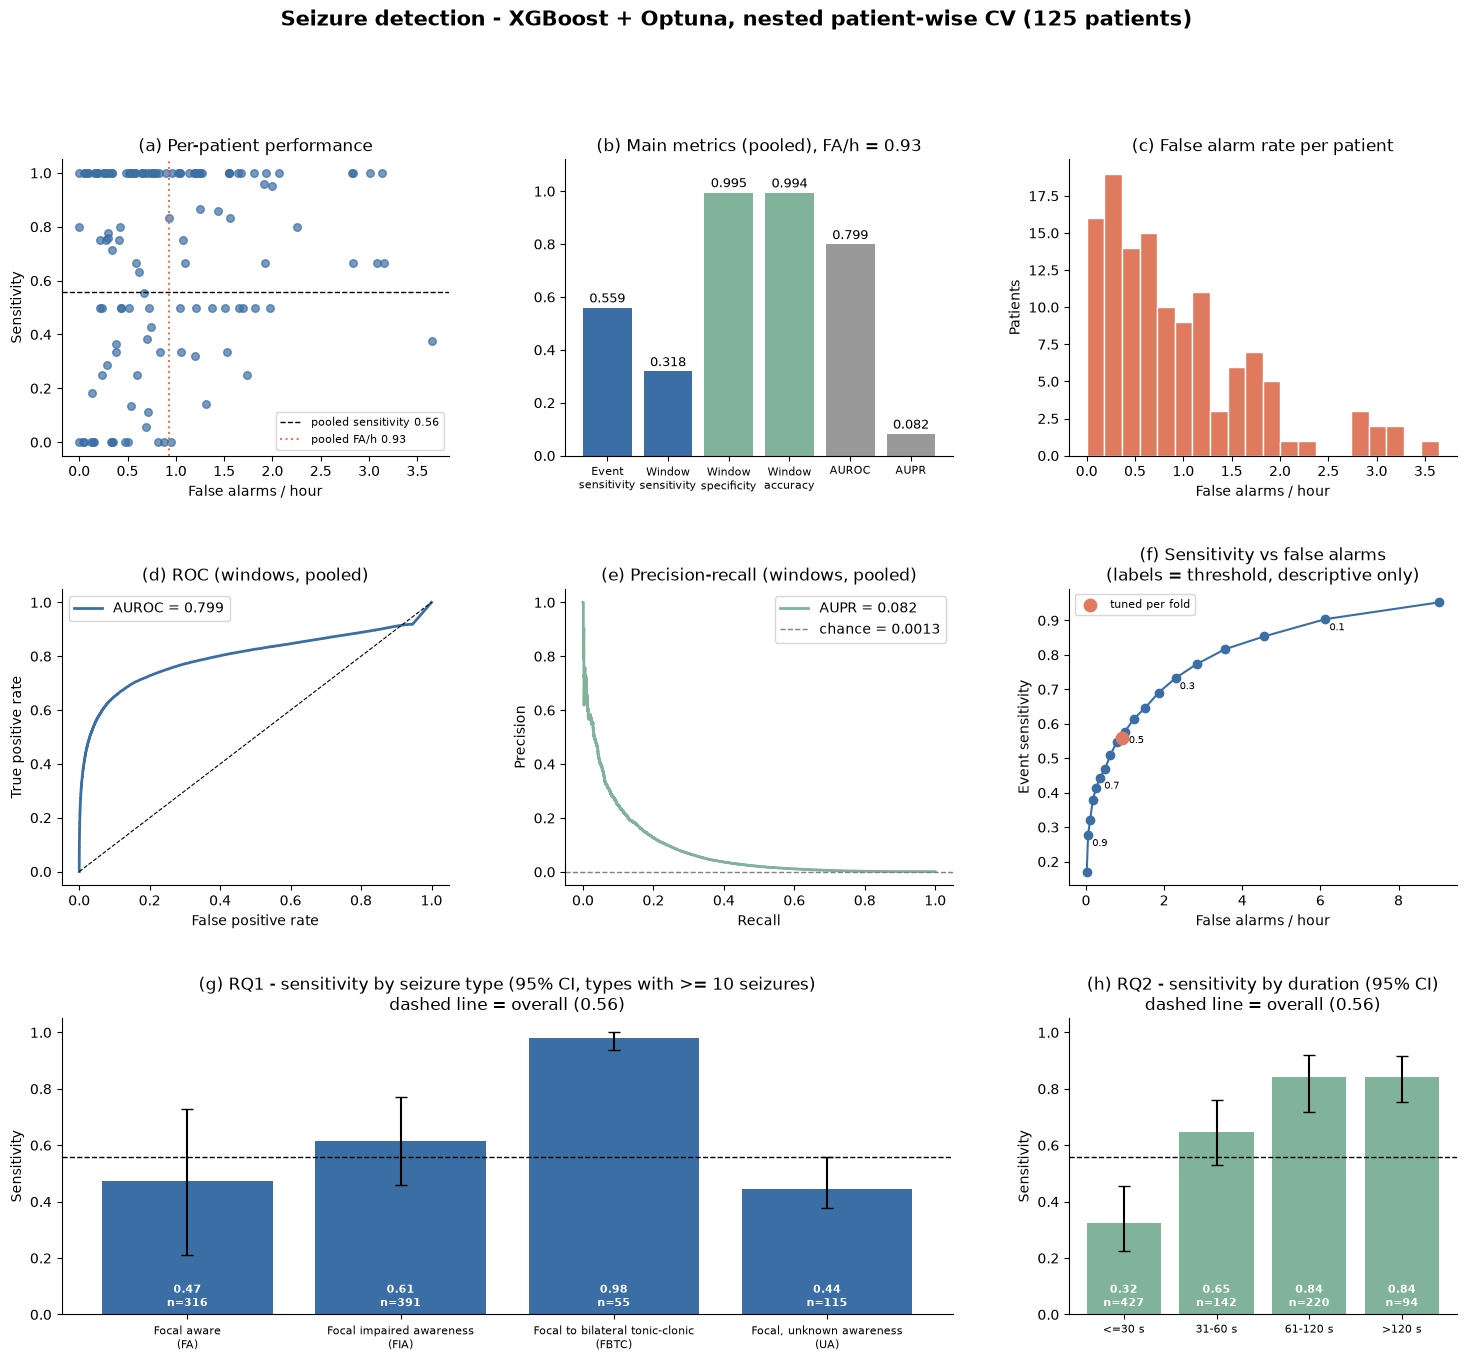

In [ ]:
# CELL 10: Result figures

from sklearn.metrics import roc_curve, precision_recall_curve

P_RAW, P_SYS = {}, {}
for s in RES.subject:
    with np.load(FOLD_DIR / f'{s}_prob.npz') as d:
        P_RAW[s], P_SYS[s] = d['p_raw'], d['p_sys']
# ROC / PR curves: all seizure windows + a random sample of background windows per patient, weighted so that the
# curves equal those of the full data (needed to fit in 4 GB RAM with tens of millions of windows).
_rng = np.random.default_rng(0); _yy, _pp, _ww = [], [], []
for s in RES.subject:
    y_, p_ = EVALS[s].y, np.where(EVALS[s].valid, P_RAW[s], 0)
    pos, neg = np.flatnonzero(y_ == 1), np.flatnonzero(y_ == 0)
    sel = _rng.choice(neg, min(len(neg), 20_000), replace=False)
    _yy += [y_[pos], y_[sel]]; _pp += [p_[pos], p_[sel]]
    _ww += [np.ones(len(pos)), np.full(len(sel), len(neg) / max(len(sel), 1))]
yy, pp, ww = np.concatenate(_yy), np.concatenate(_pp), np.concatenate(_ww)

fig = plt.figure(figsize=(18, 15)); gs = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.3)
C1, C2, C3 = '#3A6EA5', '#E07A5F', '#81B29A'

# (a) per-subject sensitivity vs FA/h
ax = fig.add_subplot(gs[0, 0])
ax.scatter(RES.fa_per_hour, RES.sensitivity, s=30, alpha=.7, color=C1)
ax.axhline(sens, ls='--', c='k', lw=1, label=f'pooled sensitivity {sens:.2f}')
ax.axvline(fa / hrs, ls=':', c=C2, lw=1.5, label=f'pooled FA/h {fa / hrs:.2f}')
ax.set_xlabel('False alarms / hour'); ax.set_ylabel('Sensitivity'); ax.set_title('(a) Per-patient performance'); ax.legend(fontsize=8)

# (b) main metrics (pooled)
ax = fig.add_subplot(gs[0, 1])
names = ['Event\nsensitivity', 'Window\nsensitivity', 'Window\nspecificity', 'Window\naccuracy', 'AUROC', 'AUPR']
vals  = [sens, wtp / (wtp + wfn), wtn / (wtn + wfp), (wtp + wtn) / (wtp + wtn + wfp + wfn),
         roc_auc_score(yy, pp, sample_weight=ww), average_precision_score(yy, pp, sample_weight=ww)]
b_ = ax.bar(names, vals, color=[C1, C1, C3, C3, '#999999', '#999999'])
for r_, v_ in zip(b_, vals): ax.text(r_.get_x() + r_.get_width() / 2, v_ + 0.02, f'{v_:.3f}', ha='center', fontsize=9)
ax.set_ylim(0, 1.12); ax.tick_params(axis='x', labelsize=8)
ax.set_title(f'(b) Main metrics (pooled), FA/h = {fa / hrs:.2f}')

# (c) distribution of per-subject FA/h
ax = fig.add_subplot(gs[0, 2])
ax.hist(RES.fa_per_hour, bins=20, color=C2, edgecolor='w')
ax.set_xlabel('False alarms / hour'); ax.set_ylabel('Patients'); ax.set_title('(c) False alarm rate per patient')

# (d) ROC  (e) PR, pooled windows
ax = fig.add_subplot(gs[1, 0])
fpr, tpr, _ = roc_curve(yy, pp, sample_weight=ww)
ax.plot(fpr, tpr, c=C1, lw=2, label=f'AUROC = {roc_auc_score(yy, pp, sample_weight=ww):.3f}'); ax.plot([0, 1], [0, 1], 'k--', lw=.8)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('(d) ROC (windows, pooled)'); ax.legend()
ax = fig.add_subplot(gs[1, 1])
pr, rc, _ = precision_recall_curve(yy, pp, sample_weight=ww)
ax.plot(rc, pr, c=C3, lw=2, label=f'AUPR = {average_precision_score(yy, pp, sample_weight=ww):.3f}')
ax.axhline(np.average(yy, weights=ww), c='gray', ls='--', lw=1, label=f'chance = {np.average(yy, weights=ww):.4f}')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('(e) Precision-recall (windows, pooled)'); ax.legend()

# (f) threshold trade-off on the out-of-fold probabilities (8/10 rule applied)
ax = fig.add_subplot(gs[1, 2])
ev_list = [EVALS[s] for s in RES.subject]
grid = np.round(np.arange(0.05, 0.951, 0.05), 2)
s_c, f_c = sweep(ev_list, P_SYS, grid)
ax.plot(f_c, s_c, 'o-', c=C1)
for g_, x_, y_ in zip(grid, f_c, s_c):
    if round(g_ * 100) % 20 == 10: ax.annotate(f'{g_:.1f}', (x_, y_), fontsize=7, xytext=(3, -8), textcoords='offset points')
ax.scatter([fa / hrs], [sens], c=C2, s=80, zorder=5, label='tuned per fold')
ax.set_xlabel('False alarms / hour'); ax.set_ylabel('Event sensitivity')
ax.set_title('(f) Sensitivity vs false alarms\n(labels = threshold, descriptive only)'); ax.legend(fontsize=8)

# (g) RQ1, (h) RQ2
def bar_ci(ax, g, title, color):
    x = np.arange(len(g))
    ax.bar(x, g.sensitivity, color=color, yerr=[g.sensitivity - g.ci_low, g.ci_high - g.sensitivity], capsize=4)
    for i, (sv, n) in enumerate(zip(g.sensitivity, g.n)):
        ax.text(i, 0.03, f'{sv:.2f}\nn={n}', ha='center', fontsize=8, color='w', fontweight='bold')
    ax.axhline(sens, ls='--', c='k', lw=1)
    ax.set_xticks(x); ax.set_xticklabels([str(i).replace(' (', '\n(') for i in g.index], fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_ylabel('Sensitivity'); ax.set_title(f'{title}\ndashed line = overall ({sens:.2f})')
bar_ci(fig.add_subplot(gs[2, 0:2]), RQ1[RQ1.n >= 10], '(g) RQ1 - sensitivity by seizure type (95% CI, types with >= 10 seizures)', C1)
bar_ci(fig.add_subplot(gs[2, 2]), RQ2, '(h) RQ2 - sensitivity by duration (95% CI)', C3)

for a in fig.axes: a.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'Seizure detection - XGBoost + Optuna, nested patient-wise CV ({len(RES)} patients)', fontsize=15, fontweight='bold')
plt.savefig(FIG_DIR / 'results_overview.png', dpi=150, bbox_inches='tight'); plt.show()

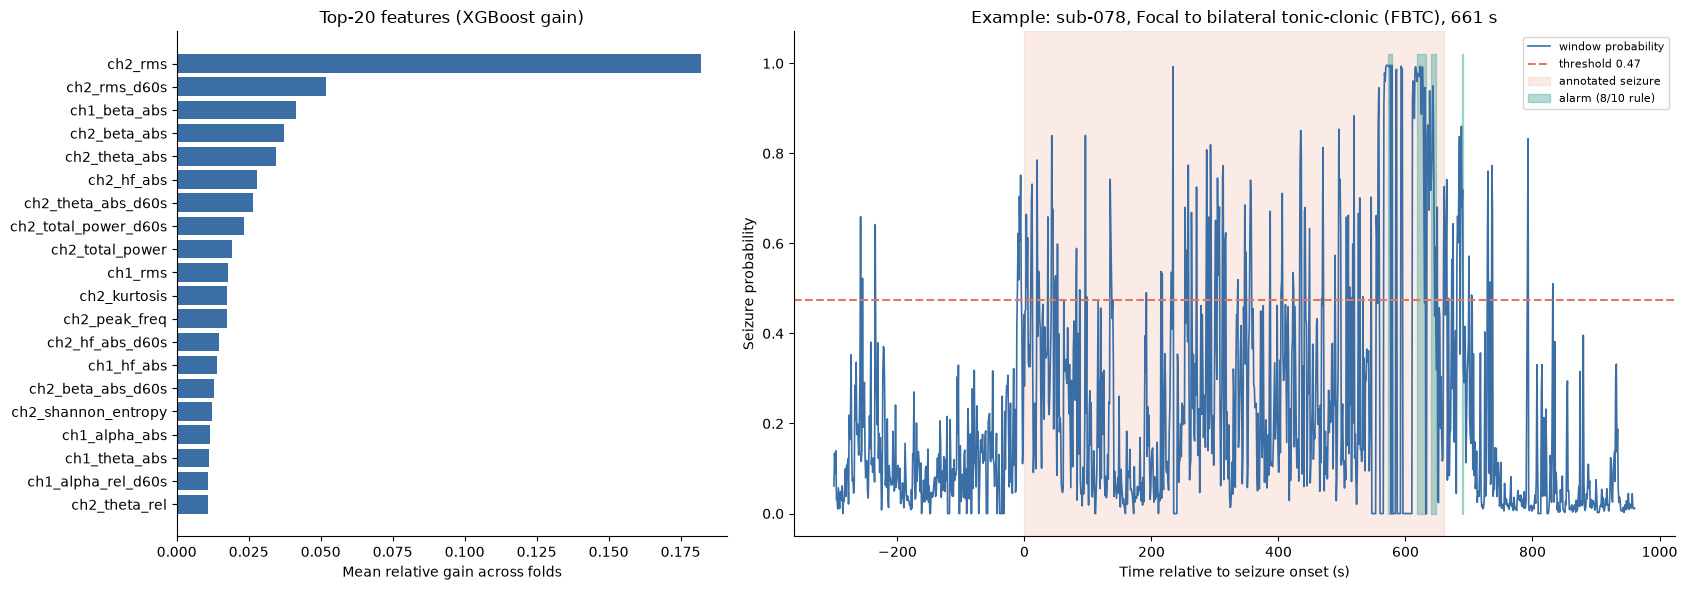

In [ ]:
# CELL 10b: Feature importance and an example detection
==
imp = pd.DataFrame([{MODEL_FEATURE_NAMES[int(k[1:])]: v for k, v in f['importance'].items()} for f in folds]).fillna(0)
imp = (imp.div(imp.sum(1), axis=0)).mean().sort_values(ascending=False)
imp.to_csv(RESULTS_DIR / 'feature_importance.csv')

fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1.6]))
top = imp.head(20)[::-1]
ax[0].barh(top.index, top.values, color='#3A6EA5'); ax[0].set_xlabel('Mean relative gain across folds')
ax[0].set_title('Top-20 features (XGBoost gain)')

# example: the longest detected seizure, +-5 min
row = SZ[SZ.detected].sort_values('duration').iloc[-1] if SZ.detected.any() else SZ.iloc[0]
s = row.subject; e = EVALS[s]; ev = REC[s]['ev']
ei = ev[(ev.type == row.type) & np.isclose(ev.duration, row.duration)].index[0]
fid, on, du = ev.loc[ei, 'file'], ev.loc[ei, 'onset'], ev.loc[ei, 'duration']
fold_res = RES.set_index('subject').loc[s]
m = (e.f == fid) & (e.t >= on - 300) & (e.t <= on + du + 300)
al = e.alarm(P_SYS[s], fold_res.threshold)[m]
ax[1].plot(e.t[m] - on, P_SYS[s][m], c='#3A6EA5', lw=1.2, label='window probability')
ax[1].axhline(fold_res.threshold, c='#E07A5F', ls='--', label=f'threshold {fold_res.threshold:.2f}')
ax[1].axvspan(0, du, color='#E07A5F', alpha=.15, label='annotated seizure')
ax[1].fill_between(e.t[m] - on, 0, 1.02, where=al, color='#2A9D8F', alpha=.35, step='post',
                   label=f'alarm ({ALARM_K}/{ALARM_N} rule)')
ax[1].set_xlabel('Time relative to seizure onset (s)'); ax[1].set_ylabel('Seizure probability')
ax[1].set_title(f'Example: {s}, {row.group}, {du:.0f} s'); ax[1].legend(fontsize=8)
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'features_and_example.png', dpi=150, bbox_inches='tight'); plt.show()

## 10c. Additional analyses

1. **Baseline vs. temporal context** – sensitivity/false-alarm curves of both models (fixed thresholds, out-of-fold
   predictions) with the operating points of Section 7. The SeizeIT2 SVM result is shown for orientation only: it
   was obtained on a different validation set and its false alarms may be counted differently.
2. **Detection latency** – time from the annotated seizure onset to the first alarm (the decision is available at the
   end of the window). Negative values: the alarm came before the annotated onset (allowed up to 30 s by SzCORE).
3. **Missed seizures per patient** – are the missed seizures spread over all patients or concentrated in a few?
4. **Duration by seizure type** – seizure types differ in duration, so RQ1 and RQ2 are not independent.
5. **Window-level confusion matrix** (main operating point) and **model AUROC per fold** (training vs. test patients,
   an over-fitting check per fold).

Latency computed for 494 seizures (detected at the main operating point: 494)
Detection latency: median 19 s, IQR 10-36 s; 69 % detected within 30 s of onset


,count,25%,50%,75%
group,,,,
Focal aware (FA),149.0,10.0,20.0,39.0
Focal impaired awareness (FIA),240.0,10.0,18.0,31.0
Focal to bilateral tonic-clonic (FBTC),54.0,14.0,23.0,37.0
"Focal, unknown awareness (UA)",51.0,10.0,21.0,40.0


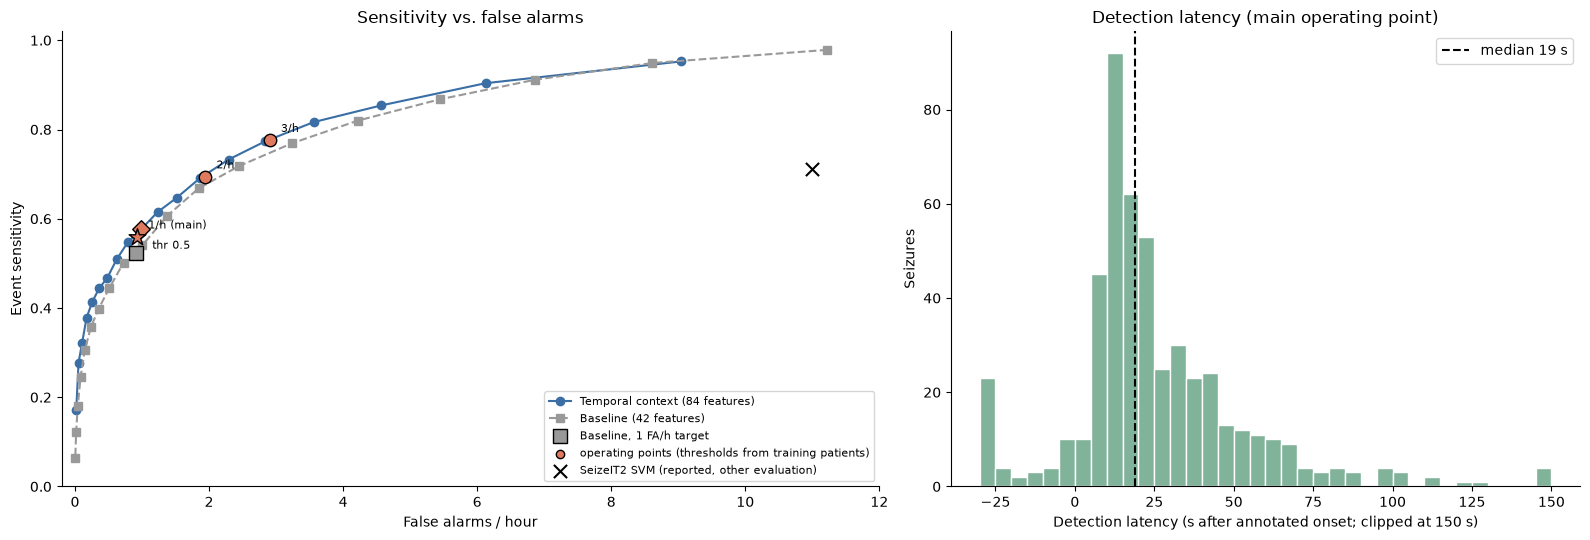

In [ ]:

# CELL 10c-1: Baseline vs. temporal context + detection latency

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw=dict(width_ratios=[1.3, 1]))

# trade-off curves 
ax[0].plot(f_c, s_c, 'o-', c=C1, label=f'Temporal context ({len(MODEL_FEATURE_NAMES)} features)')
base_ok = (BASELINE_RESULTS_DIR / 'per_subject_results.csv').exists() and \
          BASELINE_RESULTS_DIR.resolve() != RESULTS_DIR.resolve()
if base_ok:
    P_BASE = {}
    for s in RES.subject:
        with np.load(BASELINE_RESULTS_DIR / 'loso_folds' / f'{s}_prob.npz') as d:
            P_BASE[s] = d['p_sys']
    s_b, f_b = sweep(ev_list, P_BASE, grid)
    del P_BASE
    ax[0].plot(f_b, s_b, 's--', c='#999999', label='Baseline (42 features)')
    rb = pd.read_csv(BASELINE_RESULTS_DIR / 'per_subject_results.csv')
    ax[0].scatter([rb.n_false_alarms.sum() / rb.hours.sum()], [rb.n_detected.sum() / rb.n_seizures.sum()],
                  marker='s', s=90, c='#999999', edgecolor='k', zorder=5, label='Baseline, 1 FA/h target')
short = ['thr 0.5', f'{FA_TARGET_PER_H:g}/h (main)'] + [f'{t:g}/h' for t in EXTRA_FA_TARGETS]
for col, mk, lab in zip(COMP.columns[1:], ['D', '*', 'o', 'o'], short):
    ax[0].scatter(COMP.loc['FA / hour', col], COMP.loc['Event sensitivity', col], s=160 if mk == '*' else 80,
                  marker=mk, c=C2, edgecolor='k', zorder=6)
    ax[0].annotate(lab, (COMP.loc['FA / hour', col], COMP.loc['Event sensitivity', col]),
                   xytext=(8, -14 if mk == 'D' else 6), textcoords='offset points', fontsize=8)
ax[0].scatter([], [], marker='o', c=C2, edgecolor='k', label='operating points (thresholds from training patients)')
ax[0].scatter([11.0], [0.711], marker='x', s=90, c='k', zorder=6, label='SeizeIT2 SVM (reported, other evaluation)')
ax[0].set_xlim(-0.2, 12); ax[0].set_ylim(0, 1.02)
ax[0].set_xlabel('False alarms / hour'); ax[0].set_ylabel('Event sensitivity')
ax[0].set_title('Sensitivity vs. false alarms'); ax[0].legend(fontsize=8, loc='lower right')

# detection latency at the main operating point 
thr_of = RES.set_index('subject').threshold
delays = []
for s in RES.subject:
    e, ev = EVALS[s], REC[s]['ev']
    for idx, ref, ev_idx in e.files:
        if not len(ref):
            continue
        hyp = alarm_events(k_of_n(P_SYS[s][idx] >= thr_of[s]), e.t[idx])
        if not len(hyp):
            continue
        for (on, end), j in zip(ref, ev_idx):
            hit = hyp[(hyp[:, 0] < end + TOL_AFTER_SEC) & (hyp[:, 1] > on - TOL_BEFORE_SEC)]
            if len(hit):
                delays.append(dict(subject=s, group=seizure_group(ev.loc[j, 'type']), duration=ev.loc[j, 'duration'],
                                   delay=hit[:, 0].min() + WINDOW_SEC - on))
DEL = pd.DataFrame(delays)
DEL.to_csv(RESULTS_DIR / 'detection_latency.csv', index=False)
print(f'Latency computed for {len(DEL)} seizures (detected at the main operating point: {int(SZ.detected.sum())})')
print(f'Detection latency: median {DEL.delay.median():.0f} s, IQR {DEL.delay.quantile(.25):.0f}-{DEL.delay.quantile(.75):.0f} s; '
      f'{100 * (DEL.delay <= 30).mean():.0f} % detected within 30 s of onset')
display(DEL.groupby('group').delay.describe()[['count', '25%', '50%', '75%']].round(0))
ax[1].hist(DEL.delay.clip(-30, 150), bins=np.arange(-30, 155, 5), color=C3, edgecolor='w')
ax[1].axvline(DEL.delay.median(), c='k', ls='--', label=f'median {DEL.delay.median():.0f} s')
ax[1].set_xlabel('Detection latency (s after annotated onset; clipped at 150 s)'); ax[1].set_ylabel('Seizures')
ax[1].set_title('Detection latency (main operating point)'); ax[1].legend()
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'tradeoff_and_latency.png', dpi=150, bbox_inches='tight'); plt.show()

                                        count   25%    50%    75%
group                                                            
Focal aware (FA)                        316.0  13.0   32.0   89.0
Focal impaired awareness (FIA)          391.0  16.0   33.0   70.0
Focal to bilateral tonic-clonic (FBTC)   55.0  88.0  108.0  146.0
Focal, unknown awareness (UA)           115.0  10.0   14.0   34.0


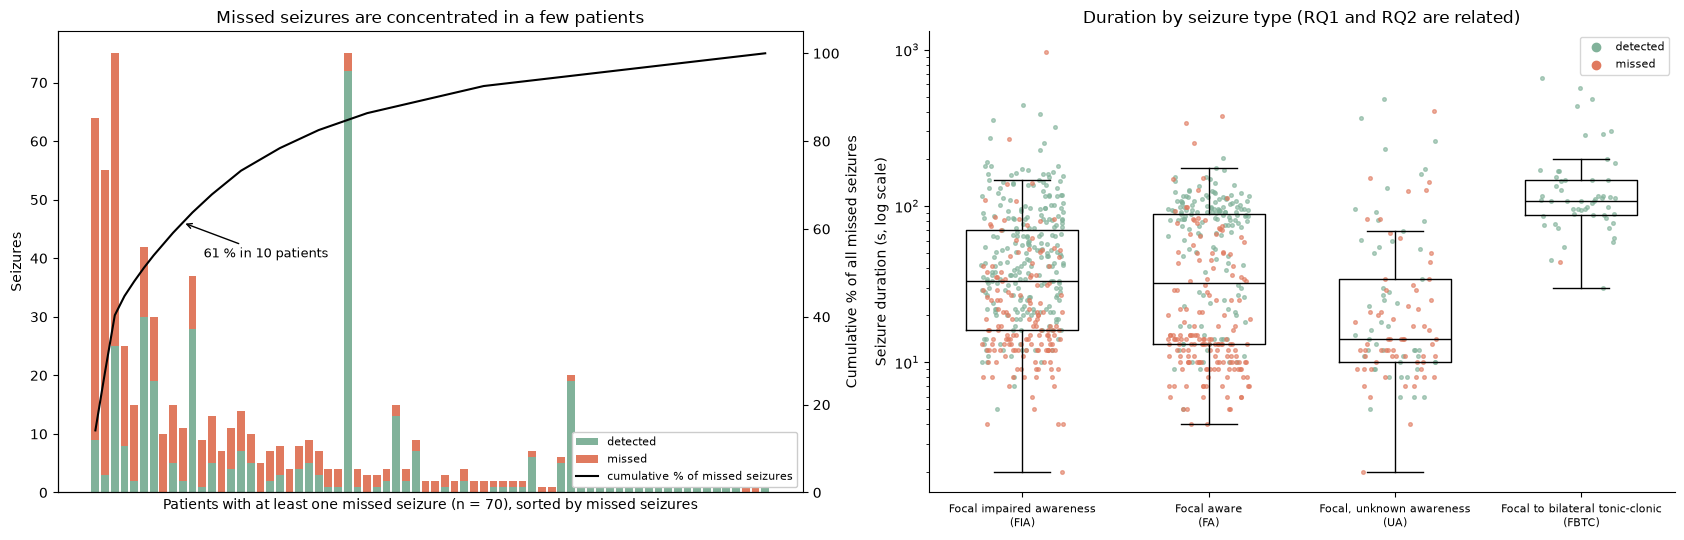

In [ ]:
# CELL 10c-2: Missed seizures per patient + duration by seizure type

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))

#  missed seizures per patient (patients sorted by number of missed seizures) 
pm = RES[['subject', 'n_seizures', 'n_detected']].copy()
pm['missed'] = pm.n_seizures - pm.n_detected
pm = pm[pm.missed > 0].sort_values('missed', ascending=False).reset_index(drop=True)
x = np.arange(len(pm))
ax[0].bar(x, pm.n_detected, color=C3, label='detected')
ax[0].bar(x, pm.missed, bottom=pm.n_detected, color=C2, label='missed')
ax[0].set_xlabel(f'Patients with at least one missed seizure (n = {len(pm)}), sorted by missed seizures')
ax[0].set_ylabel('Seizures'); ax[0].set_xticks([])
axb = ax[0].twinx()
cum = 100 * pm.missed.cumsum() / pm.missed.sum()
axb.plot(x, cum, c='k', lw=1.5, label='cumulative % of missed seizures'); axb.set_ylim(0, 105)
axb.set_ylabel('Cumulative % of all missed seizures')
k10 = min(10, len(pm)) - 1
axb.annotate(f'{cum.iloc[k10]:.0f} % in {k10 + 1} patients', (k10, cum.iloc[k10]), xytext=(15, -25),
             textcoords='offset points', arrowprops=dict(arrowstyle='->'), fontsize=9)
h1, l1 = ax[0].get_legend_handles_labels(); h2, l2 = axb.get_legend_handles_labels()
ax[0].legend(h1 + h2, l1 + l2, fontsize=8, loc='lower right', framealpha=1)
ax[0].set_title('Missed seizures are concentrated in a few patients')

#duration by seizure type, detected vs missed
groups = [g for g in SZ.group.value_counts().index if (SZ.group == g).sum() >= 10]
rng_ = np.random.default_rng(0)
for i, g in enumerate(groups):
    d = SZ[SZ.group == g]
    ax[1].boxplot(d.duration, positions=[i], widths=0.6, showfliers=False, medianprops=dict(color='k'))
    jit = rng_.uniform(-0.22, 0.22, len(d))
    ax[1].scatter(i + jit[d.detected.values], d.duration[d.detected], s=7, c=C3, alpha=.6)
    ax[1].scatter(i + jit[~d.detected.values], d.duration[~d.detected], s=7, c=C2, alpha=.6)
ax[1].scatter([], [], c=C3, label='detected'); ax[1].scatter([], [], c=C2, label='missed')
ax[1].set_yscale('log'); ax[1].set_xticks(range(len(groups)))
ax[1].set_xticklabels([g.replace(' (', '\n(') for g in groups], fontsize=8)
ax[1].set_ylabel('Seizure duration (s, log scale)'); ax[1].legend(fontsize=8)
ax[1].set_title('Duration by seizure type (RQ1 and RQ2 are related)')
print(SZ[SZ.group.isin(groups)].groupby('group').duration.describe()[['count', '25%', '50%', '75%']].round(0))
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'missed_per_patient_and_duration_by_type.png', dpi=150, bbox_inches='tight'); plt.show()

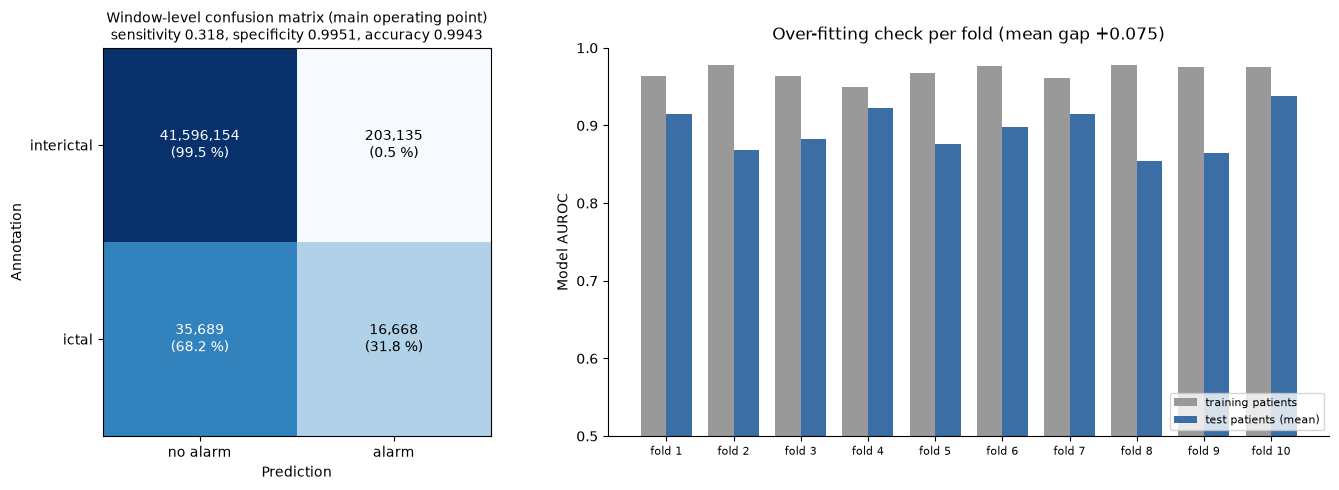

In [ ]:
# CELL 10c-3: Window-level confusion matrix + over-fitting check per fold

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1, 1.4]))

cm = np.array([[wtn, wfp], [wfn, wtp]])
ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        pct = 100 * cm[i, j] / cm[i].sum()
        ax[0].text(j, i, f'{cm[i, j]:,}\n({pct:.1f} %)', ha='center', va='center', fontsize=10,
                   color='w' if pct > 50 else 'k')
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['no alarm', 'alarm'])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(['interictal', 'ictal'])
ax[0].set_xlabel('Prediction'); ax[0].set_ylabel('Annotation')
ax[0].set_title(f'Window-level confusion matrix (main operating point)\n'
                f'sensitivity {wtp / (wtp + wfn):.3f}, specificity {wtn / (wtn + wfp):.4f}, '
                f'accuracy {(wtp + wtn) / cm.sum():.4f}', fontsize=10)

pf = RES.groupby('fold').agg(train=('train_auroc', 'first'), test=('model_auroc', 'mean')).reset_index()
xx = np.arange(len(pf)); w = 0.38
ax[1].bar(xx - w / 2, pf.train, w, color='#999999', label='training patients')
ax[1].bar(xx + w / 2, pf.test, w, color=C1, label='test patients (mean)')
ax[1].set_xticks(xx); ax[1].set_xticklabels([f'fold {k + 1}' for k in pf.fold], fontsize=8)
ax[1].set_ylim(0.5, 1.0); ax[1].set_ylabel('Model AUROC')
ax[1].set_title(f'Over-fitting check per fold (mean gap {(pf.train - pf.test).mean():+.3f})')
ax[1].legend(fontsize=8, loc='lower right')
for a in ax[1:]: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'confusion_and_overfitting.png', dpi=150, bbox_inches='tight'); plt.show()

## 10d. Cross-check of the event scoring with the official SzCORE library

Event-level scoring is implemented in Section 5. Here the same alarms are scored with the reference implementation
of SzCORE, the `timescoring` package (Dan et al., 2024; `pip install timescoring`), with its default parameters
(identical to ours). One difference is expected: `timescoring` also merges *annotated seizures* closer than 90 s
into one event, so it can count slightly fewer seizures.

In [ ]:
# CELL 10d: Cross-check with the official SzCORE scoring library (timescoring)

try:
    from timescoring import scoring as ts_scoring
    from timescoring.annotations import Annotation
except ImportError:
    ts_scoring = None
    print('timescoring is not installed - run  pip install timescoring  to perform this check.')

if ts_scoring is not None:
    FS_TS = 10
    tot = dict(ref=0, tp=0, fp=0)
    for s in RES.subject:
        e, thr_s = EVALS[s], float(RES.set_index('subject').threshold[s])
        file_ids = np.unique(e.f)
        for (idx, ref, _), fid in zip(e.files, file_ids):
            dur = float(REC[s]['file_dur'][fid])
            a_ = k_of_n(P_SYS[s][idx] >= thr_s)
            d_ = np.diff(np.concatenate([[0], a_.astype(np.int8), [0]]))
            st, en = np.flatnonzero(d_ == 1), np.flatnonzero(d_ == -1) - 1
            hyp = [(float(e.t[idx][i]), min(float(e.t[idx][j]) + WINDOW_SEC, dur)) for i, j in zip(st, en)]
            refl = [(max(0.0, float(on)), min(float(end), dur)) for on, end in ref]
            n_ = int(round(dur * FS_TS))
            r_ = ts_scoring.EventScoring(Annotation(refl, FS_TS, n_), Annotation(hyp, FS_TS, n_))
            tot['ref'] += r_.refTrue; tot['tp'] += r_.tp; tot['fp'] += r_.fp
    CHK = pd.DataFrame({'this notebook': [len(SZ), int(SZ.detected.sum()), int(RES.n_false_alarms.sum())],
                        'timescoring (SzCORE)': [tot['ref'], tot['tp'], tot['fp']]},
                       index=['seizure events', 'detected', 'false alarms'])
    CHK.loc['sensitivity'] = CHK.loc['detected'] / CHK.loc['seizure events']
    CHK.loc['FA / hour'] = CHK.loc['false alarms'] / RES.hours.sum()
    display(CHK.round(3))
    CHK.to_csv(RESULTS_DIR / 'szcore_crosscheck.csv')

,this notebook,timescoring (SzCORE)
seizure events,883.000,873.000
detected,494.000,497.000
false alarms,10790.000,10790.000
sensitivity,0.559,0.569
FA / hour,0.928,0.928


## 10e. All models that were tried

| Model | Event sensitivity | False alarms / hour |
|---|---|---|
| SVM + grid search (earlier pipeline) | not comparable (earlier pipeline); no superiority of XGBoost claimed | – |
| XGBoost, 42 features, RMS 13 µV | 0.420 | 0.93 |
| XGBoost, 42 features, RMS 2 µV + 8/10 rule (baseline) | 0.523 | 0.90 |
| **XGBoost, 84 features with temporal context (final)** | **0.559** | **0.93** |
| ↳ same final model, fixed threshold 0.5 (paper) | 0.576 | 0.99 |
| ↳ same final model, false-alarm target 2 / hour | 0.694 | 1.94 |
| ↳ same final model, false-alarm target 3 / hour | 0.776 | 2.91 |

All XGBoost models: nested patient-wise 10-fold cross-validation, Optuna (15 trials per fold), seed 42,
false-alarm target 1 per hour (main result) unless stated otherwise.

## 11. Interpretation guide and limitations

**Reading the results**

* The headline numbers are **event sensitivity** and **false alarms per hour** (pooled). Window accuracy and
  specificity are reported for completeness but are dominated by the >99 % interictal windows.
* Panel (f) shows the trade-off between sensitivity and false alarms if a single fixed threshold were used for all
  patients. It is computed from out-of-fold predictions and is descriptive; the reported numbers come from the
  thresholds chosen on the training patients of each fold.
* The over-fitting check in Cell 7 compares training, validation and test performance; a small gap means the model
  generalises to new patients.

**Limitations**

* Only two behind-the-ear channels are used; seizures without a clear scalp EEG correlate behind the ear
  (often focal aware seizures) are hard to detect by design.
* The model is patient-independent (no personalisation). Per-patient threshold adaptation usually reduces false
  alarms considerably.
* The RMS artifact rule deviates from the SeizeIT2 baseline (2 instead of 13 µV lower bound, see Section 2); the
  upper bound (150 µV) can still suppress parts of high-amplitude seizures (e.g. tonic-clonic).
* In 18 % of the recordings (patients with suspected generalised onset) channel 2 is a contralateral BTE channel
  instead of the cross-head channel; the model treats it as the same input.
* Seizures within one patient are not independent; confidence intervals therefore use a patient-level bootstrap,
  and the seizure-level McNemar test is complemented by patient-level tests (Section 9b).
* `participants.tsv` contains only sex – the recording centre (5 hospitals) is not available, so centre/batch
  effects could not be assessed and no centre-wise split was possible.
* Two design choices (RMS lower bound, temporal context) were made after earlier results on the same patients had
  been seen (Section 10e); a small optimistic bias cannot be excluded without an independent test set.
* Event scoring is our implementation of the SzCORE rules; it is cross-checked with the official `timescoring`
  package in Section 10d.
* 10 patient-wise folds are used instead of 125 leave-one-out folds, and Optuna uses one inner train/validation
  split per fold with a limited number of trials, to keep the run time feasible on a laptop.
* Hyper-parameters are tuned for AUPR (window level), while the clinical goal is event-level; the threshold step
  links the two.